# Real IBM Quantum PINN — eight simultaneous replicas

This standalone Ubuntu/WSL Jupyter notebook is based on `run_quantumAerTrain_vol2`.
It uses **real IBM Runtime SamplerV2 measurements**, never Aer or a fake backend.
The default pilot performs **one optimizer outer step**, with **1,024 shots**, then
runs the matched classical PINN and final-time comparison. The first 100 outer
steps use AdamW (initial LR 0.003); step 101 switches to L-BFGS (LR 0.5).

## Scientific meaning of the parallel experiment

Eight disjoint, connected physical paths each host the same ten-qubit RX + one
brickwork CNOT circuit. A single composite shot measures all eight regions.
There are **128 TOTAL PDE training points**, not 128 per replica. The 256 initial
condition points are separate. One pair of classical pre/post networks shares its
weights across regions, but **each physical region has its own full trigonometric
surrogate**. Points carry explicit region IDs; every FD neighbor uses its center's
region, and repeated validation measurements keep exactly the same assignments.
Thus this is a shared-weight experiment over coordinate/physical-region pairs.
It does not assume that eight noisy hardware regions implement the same function.

The 1,024 initial calibration angle sets are measured in **each** region. Their
orders are independently shuffled across regions, while all eight execute together.
Only initial calibration and end-of-block TRAINING observations fit the polynomials.
Validation, diagnostics, and final plots never enter calibration or optimization.
Real cross-talk/drift can violate the local stationary-channel approximation:
held-out feature errors and independent measured validation remain essential.

The final figure shows every physical replica and their descriptive mean. The
mean curve's nonlinear Burgers residual is NOT the objective being optimized.
The classical PINN replays the actual saved hybrid collocation schedule and uses
the same physics, initial-condition penalty, FD stencil and optimizer phase boundary.
Each model has its own validation-driven Adam scheduler; outer-step costs differ.

## Execution and recovery

1. Run dependencies, definitions and configuration. Configure an existing IBM
   account, or an environment token and instance. No token is stored in artifacts.
2. Run preparation: inspect eight paths, the compiled circuit report and the budget.
   This reads backend metadata and saves local files, but submits no jobs.
3. Run training: **this cell submits paid/allocated real QPU jobs**. Job IDs, exact
   inputs, region assignments, raw bitstrings/counts and results are saved durably.
4. Run the classical comparison and final evaluation cells.

To continue the pilot, set `ACTION="resume"`, `ADAM_EPOCHS=500` and
`RESUME_CHECKPOINT` to its printed `checkpoint_last.pt`. Keep the 100-step phase
boundary and all scientific settings unchanged. Run preparation/training again.
An interrupted epoch reuses its existing job results; canceled/failed jobs are
never automatically resubmitted. Detailed recovery examples are at the end.

Outputs go into a NEW `CBPF_quantum_ibm_training_results_vol2_parallel8` folder.
Every completed epoch has its full checkpoint and a weights-only NPZ. The original
Aer notebook and previous result folders are not modified.


In [1]:
# This cell reports dependencies and never installs anything.
import sys
from importlib.metadata import version, PackageNotFoundError
print("Python:", sys.executable)
for package in ("numpy", "torch", "matplotlib", "networkx", "qiskit", "qiskit-ibm-runtime"):
    try:
        print(package, version(package))
    except PackageNotFoundError:
        print(package, "MISSING in this Jupyter kernel")
# If needed, install these in the SAME WSL/Jupyter environment before continuing.
# qiskit-aer and scienceplots are not required.


Python: /home/erickcastro/venvs/qiskit-ml/bin/python
numpy 2.4.2
torch 2.9.1+cu128
matplotlib 3.10.8
networkx 3.6.1
qiskit 2.3.0
qiskit-ibm-runtime 0.50.0


In [2]:
"""Real Heron r3 parallel PINN trainer. Import never authenticates or submits jobs."""
from __future__ import annotations


# === RUNTIME ===
"""Topology-aware, recoverable Runtime execution of disjoint circuit replicas.

Import does not authenticate or submit. Every acquisition persists exact inputs,
packing identities, submission intent, job IDs, counts and paired raw bitstrings.
"""

import hashlib
import importlib.metadata
import json
import math
import os
import uuid
from datetime import datetime, timezone
from contextlib import contextmanager
from pathlib import Path
import numpy as np


def _pibm_now():
    return datetime.now(timezone.utc).isoformat()


def _pibm_safe(value):
    if isinstance(value, dict):
        return {str(k): _pibm_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_pibm_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return _pibm_safe(value.item())
    if isinstance(value, datetime):
        return value.isoformat()
    if value is None or isinstance(value, (str, int, bool)):
        return value
    if isinstance(value, float):
        return value if math.isfinite(value) else None
    return {"unserialized_type": type(value).__name__}


def _pibm_bytes(value):
    return json.dumps(_pibm_safe(value), sort_keys=True, separators=(",", ":"), allow_nan=False).encode()


def _pibm_atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        with temporary.open("wb") as stream:
            stream.write(_pibm_bytes(value))
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


@contextmanager
def _pibm_request_lock(path):
    """OS-managed advisory lock; process death releases ownership automatically.

    The lock file deliberately remains on disk. Its presence is not ownership,
    so restarting a Jupyter kernel never requires deleting a stale lock file.
    """
    path = Path(path)
    handle, locked = path.open("a+b"), False
    try:
        if path.stat().st_size == 0:
            handle.write(b"0")
            handle.flush()
        handle.seek(0)
        try:
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(handle.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(handle.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            locked = True
        except (OSError, BlockingIOError) as error:
            raise RuntimeError("Another process owns this QPU request; concurrent acquisition/recovery is forbidden.") from error
        yield
    finally:
        try:
            if locked:
                handle.seek(0)
                if os.name == "nt":
                    import msvcrt
                    msvcrt.locking(handle.fileno(), msvcrt.LK_UNLCK, 1)
                else:
                    import fcntl
                    fcntl.flock(handle.fileno(), fcntl.LOCK_UN)
        finally:
            handle.close()


def _pibm_atomic_npz(path, **arrays):
    path = Path(path)
    temporary = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        with temporary.open("wb") as stream:
            np.savez_compressed(stream, **arrays)
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def _pibm_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def _pibm_int(value, name, minimum=1):
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < minimum:
        raise ValueError(f"{name} must be an integer >= {minimum}.")
    return int(value)


def _pibm_name(backend):
    value = backend.name
    return str(value() if callable(value) else value)


def _pibm_processor(backend):
    value = getattr(backend, "processor_type", None)
    value = value() if callable(value) else value
    if value is None and hasattr(backend, "configuration"):
        value = getattr(backend.configuration(), "processor_type", None)
    return value or {}


def _pibm_status(job):
    value = job.status()
    return str(getattr(value, "name", value)).rsplit(".", 1)[-1].upper()


def parallel_backend_graph(backend):
    """Supported native entangling edges, with a frozen error snapshot."""
    adjacency = {i: set() for i in range(int(backend.num_qubits))}
    edges, readout, instructions = {}, {}, []
    for name in backend.target.operation_names:
        operation = backend.target.operation_from_name(name)
        if operation.num_qubits != 2 or name not in ("cx", "cz", "ecr", "rzz", "iswap", "swap"):
            continue
        for pair, properties in backend.target[name].items():
            if pair is None or len(pair) != 2:
                continue
            a, b = map(int, pair)
            error = getattr(properties, "error", None)
            error = 0.02 if error is None or not np.isfinite(error) else float(error)
            if not 0 <= error < 1:
                continue
            adjacency[a].add(b)
            adjacency[b].add(a)
            key = tuple(sorted((a, b)))
            edges[key] = min(error, edges.get(key, 1.0))
            instructions.append({"name": name, "qubits": list(pair), "error": error,
                                 "duration": getattr(properties, "duration", None)})
    if "measure" not in backend.target.operation_names:
        raise ValueError("Backend has no measurement instruction.")
    for q in adjacency:
        error = getattr(backend.target["measure"].get((q,)), "error", None)
        readout[q] = 0.05 if error is None or not np.isfinite(error) else float(error)
    return adjacency, edges, readout, instructions


def validate_parallel_layouts(layouts, adjacency, n_qubits, replicas, min_separation=1):
    """Distance 1 permits adjacent regions; distance 2 leaves a graph gap."""
    min_separation = _pibm_int(min_separation, "min_separation")
    if len(layouts) != replicas:
        raise ValueError(f"Exactly {replicas} physical paths are required.")
    cleaned, seen = [], set()
    for path in layouts:
        if len(path) != n_qubits:
            raise ValueError("Every replica must contain exactly n_qubits vertices.")
        path = [_pibm_int(q, "physical qubit", 0) for q in path]
        if len(set(path)) != len(path) or seen.intersection(path):
            raise ValueError("Physical replica paths must be unique and disjoint.")
        if any(q not in adjacency for q in path):
            raise ValueError("Physical qubit outside backend.")
        if any(b not in adjacency[a] for a, b in zip(path, path[1:])):
            raise ValueError("Replica path contains a missing entangling edge.")
        frontier, vicinity = set(path), set(path)
        for _ in range(min_separation - 1):
            frontier = set().union(*(adjacency[q] for q in frontier)) - vicinity
            vicinity.update(frontier)
        if seen.intersection(vicinity):
            raise ValueError("Replica paths violate minimum separation.")
        cleaned.append(path)
        seen.update(path)
    return cleaned


def select_parallel_layouts(backend, n_qubits=10, replicas=8, min_separation=1,
                            seed=1234, trials=256, candidates_per_start=256):
    """Bounded error-aware path packing; never silently reduces replica count."""
    n_qubits = _pibm_int(n_qubits, "n_qubits")
    replicas = _pibm_int(replicas, "replicas")
    min_separation = _pibm_int(min_separation, "min_separation")
    adjacency, edges, readout, _ = parallel_backend_graph(backend)
    if n_qubits * replicas > len(adjacency):
        raise ValueError("Insufficient physical qubits for all replicas.")
    candidates = {}
    for start in sorted(adjacency, key=lambda q: (readout[q], q)):
        produced, stack = 0, [(start,)]
        while stack and produced < candidates_per_start:
            path = stack.pop()
            if len(path) == n_qubits:
                produced += 1
                key = min(path, path[::-1])
                if key in candidates:
                    continue
                score = sum(-math.log1p(-min(readout[q], 0.999)) for q in path)
                score += sum(-math.log1p(-edges[tuple(sorted((a, b)))]) for a, b in zip(path, path[1:]))
                vicinity, frontier = set(path), set(path)
                for _ in range(min_separation - 1):
                    frontier = set().union(*(adjacency[q] for q in frontier)) - vicinity
                    vicinity.update(frontier)
                candidates[key] = (score, key, sum(1 << q for q in path), sum(1 << q for q in vicinity))
            else:
                neighbors = sorted((q for q in adjacency[path[-1]] if q not in path),
                    key=lambda q: (readout[q]+edges[tuple(sorted((q, path[-1])))], q), reverse=True)
                stack.extend(path+(q,) for q in neighbors)
    ranked = sorted(candidates.values())
    if not ranked:
        raise ValueError("No path of the requested length was found.")
    scores, rng = np.asarray([v[0] for v in ranked]), np.random.default_rng(seed)
    best, best_score = None, math.inf
    for attempt in range(trials):
        scale = (0.03, 0.10, 0.30, 1.0)[attempt % 4]
        order = np.arange(len(ranked)) if attempt == 0 else np.argsort(scores + scale*rng.gumbel(size=len(ranked)))
        chosen, occupied = [], 0
        for index in order:
            item = ranked[int(index)]
            if item[2] & occupied:
                continue
            chosen.append(item)
            occupied |= item[3]
            if len(chosen) == replicas:
                cost = sum(v[0] for v in chosen)
                if cost < best_score:
                    best_score, best = cost, [list(v[1]) for v in chosen]
                break
    if best is None:
        raise RuntimeError("Could not pack every replica. Supply validated manual paths, increase search trials, "
                           "or explicitly revise spacing. Topology and replica count are never silently relaxed.")
    return validate_parallel_layouts(best, adjacency, n_qubits, replicas, min_separation)


def compile_parallel_template(backend, layouts, input_rotation_axis="rx", optimization_level=1,
                              seed_transpiler=1234):
    from qiskit import ClassicalRegister, QuantumCircuit, transpile
    from qiskit.circuit import ParameterVector
    replicas, n = len(layouts), len(layouts[0])
    if input_rotation_axis not in ("rx", "ry"):
        raise ValueError("Input rotation must be rx or ry.")
    circuit = QuantumCircuit(replicas*n)
    parameters = ParameterVector("parallel_angle", replicas*n)
    for r in range(replicas):
        register = ClassicalRegister(n, f"replica_{r}")
        circuit.add_register(register)
        for j in range(n):
            getattr(circuit, input_rotation_axis)(parameters[r*n+j], r*n+j)
        for parity in (0, 1):
            for j in range(parity, n-1, 2):
                circuit.cx(r*n+j, r*n+j+1)
        for j in range(n):
            circuit.measure(r*n+j, register[j])
    isa = transpile(circuit, backend=backend, initial_layout=[q for path in layouts for q in path],
                    routing_method="none", optimization_level=optimization_level, seed_transpiler=seed_transpiler)
    lookup = {str(p): [i//n, i % n] for i, p in enumerate(parameters)}
    return isa, lookup, validate_parallel_template(isa, layouts, lookup)


def validate_parallel_template(isa, layouts, lookup):
    replicas, n = len(layouts), len(layouts[0])
    owner = {q: r for r, path in enumerate(layouts) for q in path}
    measurements, two_qubit_gates = {}, 0
    for item in isa.data:
        name = item.operation.name
        qs = [isa.find_bit(q).index for q in item.qubits]
        if name == "barrier":
            continue
        if any(q not in owner for q in qs):
            raise ValueError("Compiled operation escaped the selected replica paths.")
        if len(qs) > 1:
            if len(qs) != 2 or len({owner[q] for q in qs}) != 1:
                raise ValueError("Cross-replica operation in compiled circuit.")
            two_qubit_gates += 1
        if name == "swap":
            raise ValueError("Unexpected SWAP routing; physical identity must remain fixed.")
        if name == "measure":
            registers = isa.find_bit(item.clbits[0]).registers
            if len(registers) != 1:
                raise ValueError("Ambiguous classical register map.")
            reg, j = registers[0]
            r = int(reg.name.removeprefix("replica_"))
            if qs != [layouts[r][j]]:
                raise ValueError("Transpilation changed the required measurement map.")
            measurements[(r, j)] = qs[0]
        for value in item.operation.params:
            for parameter in getattr(value, "parameters", ()):
                if str(parameter) not in lookup:
                    raise ValueError("Unexpected free parameter in template.")
                r, _ = lookup[str(parameter)]
                if any(owner[q] != r for q in qs):
                    raise ValueError("Input parameter leaked into another replica.")
    if len(measurements) != replicas*n or len(isa.parameters) != replicas*n:
        raise ValueError("Compiled template lost measurements or angle parameters.")
    supports = []
    for r in range(replicas):
        outputs = []
        for j in range(n):
            cone, inputs = {measurements[(r, j)]}, set()
            for item in reversed(isa.data):
                if item.operation.name in ("barrier", "measure"):
                    continue
                qs = {isa.find_bit(q).index for q in item.qubits}
                if not cone.intersection(qs):
                    continue
                cone.update(qs)
                for value in item.operation.params:
                    for parameter in getattr(value, "parameters", ()):
                        pr, pj = lookup[str(parameter)]
                        if pr != r:
                            raise ValueError("Backward causal cone crosses replica identity.")
                        inputs.add(pj)
            outputs.append(sorted(inputs))
        supports.append(outputs)
    return {"depth": isa.depth(), "operation_counts": dict(isa.count_ops()),
            "native_two_qubit_gates": two_qubit_gates, "supports_by_replica": supports,
            "measurement_paths": layouts, "no_cross_replica_gates": True, "routing_method": "none"}


def validate_parallel_target(isa, backend):
    """Reject stale ISA instructions before any submission to a changed target."""
    for item in isa.data:
        if item.operation.name == "barrier":
            continue
        qargs = tuple(isa.find_bit(q).index for q in item.qubits)
        if not backend.target.instruction_supported(operation_name=item.operation.name, qargs=qargs):
            raise ValueError(f"Saved ISA instruction {item.operation.name}{qargs} is unsupported by the current target.")


def pack_parallel_angles(angles, replica_ids, n_qubits, replicas):
    angles, ids = np.asarray(angles, dtype=np.float64), np.asarray(replica_ids)
    if angles.ndim != 2 or angles.shape[1] != n_qubits or not np.isfinite(angles).all():
        raise ValueError("Angles must be finite [N, n_qubits].")
    if ids.shape != (len(angles),) or ids.dtype.kind not in "iu" or np.any(ids < 0) or np.any(ids >= replicas):
        raise ValueError("replica_ids must contain one valid integer per row.")
    indices = [np.flatnonzero(ids == r) for r in range(replicas)]
    rows = max((len(v) for v in indices), default=0)
    packed, row_map = np.zeros((rows, replicas, n_qubits)), np.full((rows, replicas), -1, dtype=np.int64)
    for r, source in enumerate(indices):
        packed[:len(source), r] = angles[source]
        row_map[:len(source), r] = source
    return packed, row_map


def counts_to_z_means(counts, n_qubits, shots):
    if sum(counts.values()) != shots:
        raise ValueError("Returned shots differ from requested shots.")
    means = np.zeros(n_qubits)
    for bitstring, count in counts.items():
        clean = str(bitstring).replace(" ", "")
        if len(clean) != n_qubits or set(clean)-{"0", "1"} or int(count) != count or count < 0:
            raise ValueError("Malformed per-register counts.")
        bits = np.asarray([int(c) for c in clean[::-1]])
        means += int(count)*(1-2*bits)
    return means/shots


class ParallelIBMRunner:
    """A fixed physical layout with a durable, exact-input Runtime job ledger."""

    def __init__(self, backend, service, run_dir, *, n_qubits=10, replicas=8,
                 layouts=None, min_separation=1, optimization_level=1, seed_transpiler=1234,
                 max_configs_per_job=128, input_rotation_axis="rx", sampler=None,
                 allow_submit=False, require_heron_r3=True, rep_delay=None, layout_search_trials=256):
        self.backend, self.service = backend, service
        self.run_dir = Path(run_dir)
        self.n_qubits, self.replicas = _pibm_int(n_qubits, "n_qubits"), _pibm_int(replicas, "replicas")
        self.max_configs_per_job = _pibm_int(max_configs_per_job, "max_configs_per_job")
        self.allow_submit, self.injected_sampler = bool(allow_submit), sampler
        requested_rep_delay = None if rep_delay is None else float(rep_delay)
        self.rep_delay = requested_rep_delay
        processor = _pibm_processor(backend)
        if require_heron_r3 and (str(processor.get("family", "")).lower() != "heron"
                                or str(processor.get("revision", "")) != "3"):
            raise ValueError("Select a Heron r3 backend; changing family requires an explicit protocol change.")
        if require_heron_r3:
            from qiskit_ibm_runtime import IBMBackend
            if not isinstance(backend, IBMBackend) or bool(backend.configuration().simulator):
                raise ValueError("Real execution requires an IBMBackend QPU; fake/simulator backends are for explicit offline tests only.")
        self.hardware_dir = self.run_dir / "hardware"
        self.hardware_dir.mkdir(parents=True, exist_ok=True)
        snapshot_path, qpy_path = self.hardware_dir / "hardware_manifest.json", self.hardware_dir / "parallel_template.qpy"
        from qiskit import qpy
        if snapshot_path.exists():
            saved = json.loads(snapshot_path.read_text(encoding="utf-8"))
            digest = hashlib.sha256(_pibm_bytes({k: v for k, v in saved.items() if k != "fingerprint"})).hexdigest()
            if digest != saved["fingerprint"]:
                raise ValueError("Hardware manifest checksum mismatch.")
            expected = {"backend_name": _pibm_name(backend), "backend_num_qubits": int(backend.num_qubits),
                        "n_qubits": self.n_qubits, "replicas": self.replicas,
                        "input_rotation_axis": input_rotation_axis, "min_separation": min_separation,
                        "requested_rep_delay": requested_rep_delay}
            for key, value in expected.items():
                if saved[key] != value:
                    raise ValueError(f"Saved hardware protocol mismatch for {key}.")
            if layouts is not None and [list(path) for path in layouts] != saved["layouts"]:
                raise ValueError("Resume cannot change physical layouts.")
            if _pibm_sha(qpy_path) != saved["qpy_sha256"]:
                raise ValueError("Compiled circuit checksum mismatch.")
            with qpy_path.open("rb") as stream:
                self.template = qpy.load(stream)[0]
            self.layouts, self.parameter_lookup = saved["layouts"], saved["parameter_lookup"]
            adjacency, _, _, _ = parallel_backend_graph(backend)
            validate_parallel_layouts(self.layouts, adjacency, self.n_qubits, self.replicas, min_separation)
            self.compilation_report = validate_parallel_template(self.template, self.layouts, self.parameter_lookup)
            version = str(getattr(backend, "backend_version", ""))
            if version.split(".")[:2] != saved["backend_version"].split(".")[:2]:
                raise ValueError("Backend major/minor version changed; saved compiled protocol may no longer be valid.")
            self.rep_delay = saved["rep_delay"]
            self.hardware_manifest = saved
        else:
            if qpy_path.exists():
                raise RuntimeError("Incomplete hardware setup: QPY exists without a manifest. Inspect before retrying.")
            self.rep_delay = (getattr(backend, "default_rep_delay", None)
                              if requested_rep_delay is None else requested_rep_delay)
            self._validate_rep_delay(require_heron_r3)
            adjacency, _, readout, instructions = parallel_backend_graph(backend)
            if layouts is None:
                layouts = select_parallel_layouts(backend, self.n_qubits, self.replicas,
                                                  min_separation, seed_transpiler, layout_search_trials)
            self.layouts = validate_parallel_layouts(layouts, adjacency, self.n_qubits, self.replicas, min_separation)
            self.template, self.parameter_lookup, self.compilation_report = compile_parallel_template(
                backend, self.layouts, input_rotation_axis, optimization_level, seed_transpiler)
            with qpy_path.open("wb") as stream:
                qpy.dump(self.template, stream)
                stream.flush()
                os.fsync(stream.fileno())
            try:
                properties = backend.properties()
                calibration = properties.to_dict() if properties is not None else None
            except Exception:
                calibration = None
            versions = {}
            for package in ("qiskit", "qiskit-ibm-runtime", "numpy"):
                try:
                    versions[package] = importlib.metadata.version(package)
                except importlib.metadata.PackageNotFoundError:
                    versions[package] = None
            saved = {"format": "parallel_ibm_hardware_v1", "created_at": _pibm_now(),
                     "backend_name": _pibm_name(backend), "backend_num_qubits": int(backend.num_qubits),
                     "backend_version": str(getattr(backend, "backend_version", "")), "processor_type": processor,
                     "n_qubits": self.n_qubits, "replicas": self.replicas, "layouts": self.layouts,
                     "min_separation": min_separation, "input_rotation_axis": input_rotation_axis,
                     "optimization_level": optimization_level, "seed_transpiler": seed_transpiler,
                     "requested_rep_delay": requested_rep_delay, "rep_delay": self.rep_delay, "default_rep_delay_at_setup": getattr(backend, "default_rep_delay", None),
                     "qpy_sha256": _pibm_sha(qpy_path), "parameter_lookup": self.parameter_lookup,
                     "parameter_order": [str(p) for p in self.template.parameters], "versions": versions,
                     "compilation_report": self.compilation_report, "backend_calibration": _pibm_safe(calibration),
                     "target_snapshot": {"two_qubit_instructions": instructions, "readout_errors": readout},
                     "padding_angles": 0.0,
                     "padding_warning": "Padding is excluded from observations but its physical gates still execute."}
            saved["fingerprint"] = hashlib.sha256(_pibm_bytes(saved)).hexdigest()
            _pibm_atomic_json(snapshot_path, saved)
            self.hardware_manifest = saved
        self._validate_rep_delay(require_heron_r3)
        validate_parallel_target(self.template, self.backend)
        self.identity = {"fingerprint": self.hardware_manifest["fingerprint"],
                         "backend_name": self.hardware_manifest["backend_name"],
                         "qpy_sha256": self.hardware_manifest["qpy_sha256"],
                         "layouts": self.layouts, "n_qubits": self.n_qubits, "replicas": self.replicas}
        self.compiled_circuit = self.template
        self.supports_by_replica = self.compilation_report["supports_by_replica"]
        self.last_request_dir = None

    def _validate_rep_delay(self, require_known):
        if self.rep_delay is None:
            if require_known:
                raise ValueError("Cannot freeze backend repetition delay. Set an explicit supported rep_delay.")
            return
        limits = getattr(self.backend, "rep_delay_range", None)
        if not np.isfinite(self.rep_delay) or limits is None or not limits[0] <= self.rep_delay <= limits[1]:
            raise ValueError("The frozen rep_delay is outside this backend's current supported range.")

    def _request_dir(self, request_key):
        if not isinstance(request_key, str) or not request_key:
            raise ValueError("request_key must be a nonempty stable scientific operation identifier.")
        return self.run_dir / "qpu_requests" / hashlib.sha256(request_key.encode()).hexdigest()[:24]

    def _sampler(self, tag):
        if self.injected_sampler is not None:
            sampler = self.injected_sampler
            if hasattr(sampler, "options"):
                sampler.options.environment.job_tags = [tag]
                if hasattr(sampler.options, "execution"):
                    sampler.options.execution.init_qubits = True
                    if self.rep_delay is not None:
                        sampler.options.execution.rep_delay = self.rep_delay
            return sampler
        from qiskit_ibm_runtime import SamplerV2
        options = {"environment": {"job_tags": [tag]}, "execution": {"init_qubits": True}}
        if self.rep_delay is not None:
            options["execution"]["rep_delay"] = self.rep_delay
        return SamplerV2(mode=self.backend, options=options)

    def measure(self, angles, replica_ids, *, shots, request_key, wait=True, timeout=None):
        shots = _pibm_int(shots, "shots")
        angles, ids = np.asarray(angles, dtype=np.float64), np.asarray(replica_ids)
        packed, row_map = pack_parallel_angles(angles, ids, self.n_qubits, self.replicas)
        if len(angles) == 0:
            return np.empty((0, self.n_qubits))
        directory = self._request_dir(request_key)
        directory.mkdir(parents=True, exist_ok=True)
        self.last_request_dir = directory
        with _pibm_request_lock(directory / ".request.lock"):
            return self._measure_locked(angles, ids, packed, row_map, shots, request_key, directory, wait, timeout)

    def _measure_locked(self, angles, ids, packed, row_map, shots, request_key, directory, wait, timeout):
        fingerprint = hashlib.sha256(_pibm_bytes({"hardware": self.identity, "shots": shots,
                            "request_key": request_key, "angles": angles, "replica_ids": ids})).hexdigest()
        manifest_path, means_path = directory / "request.json", directory / "means.npz"
        if manifest_path.exists():
            manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
            if manifest["fingerprint"] != fingerprint:
                raise ValueError("Existing request_key has different angles, replicas or shots.")
            if _pibm_sha(directory / "inputs.npz") != manifest["inputs_sha256"]:
                raise ValueError("Saved input checksum mismatch.")
            if manifest["state"] == "completed":
                if _pibm_sha(means_path) != manifest["means_sha256"]:
                    raise ValueError("Cached expectation checksum mismatch.")
                with np.load(means_path, allow_pickle=False) as archive:
                    return archive["means"].copy()
        else:
            _pibm_atomic_npz(directory / "inputs.npz", angles=angles, replica_ids=ids,
                             packed_angles=packed, row_map=row_map)
            chunks = []
            for start in range(0, len(packed), self.max_configs_per_job):
                index = len(chunks)
                chunks.append({"index": index, "start": start, "stop": min(start+self.max_configs_per_job, len(packed)),
                               "state": "prepared", "job_id": None, "attempt": 0,
                               "tag": "pibm-" + fingerprint[:30] + f"-{index}-0"})
            manifest = {"format": "parallel_ibm_request_v1", "request_key": request_key,
                        "fingerprint": fingerprint, "hardware_identity": self.identity,
                        "backend_name": _pibm_name(self.backend), "shots": shots,
                        "logical_rows": len(angles), "packed_configs": len(packed),
                        "padding_slots": int(np.count_nonzero(row_map < 0)),
                        "inputs_sha256": _pibm_sha(directory / "inputs.npz"),
                        "state": "prepared", "created_at": _pibm_now(), "chunks": chunks}
            _pibm_atomic_json(manifest_path, manifest)
        means = np.empty((len(angles), self.n_qubits))
        positions = [tuple(self.parameter_lookup[str(p)]) for p in self.template.parameters]
        for chunk in manifest["chunks"]:
            counts_path = directory / f"counts_chunk_{chunk['index']:04d}.json"
            bits_path = directory / f"bitstrings_chunk_{chunk['index']:04d}.npz"
            if chunk["state"] == "completed":
                if _pibm_sha(counts_path) != chunk["counts_sha256"] or _pibm_sha(bits_path) != chunk["bitstrings_sha256"]:
                    raise ValueError("Raw measurement checksum mismatch.")
                raw = json.loads(counts_path.read_text(encoding="utf-8"))
            else:
                if chunk["state"] in ("submission_intent", "submission_unknown") and chunk["job_id"] is None:
                    raise RuntimeError(f"Unknown submission outcome for {request_key}, chunk {chunk['index']}. "
                        f"Find IBM job tag {chunk['tag']} and call recover_job(); no automatic resubmission.")
                if chunk["job_id"] is None:
                    if not self.allow_submit:
                        raise RuntimeError("Submission disabled. Inspect the saved plan then explicitly enable allow_submit.")
                    validate_parallel_target(self.template, self.backend)
                    sampler = self._sampler(chunk["tag"])
                    values = np.column_stack([packed[chunk["start"]:chunk["stop"], r, j] for r, j in positions])
                    chunk.update(state="submission_intent", submitted_at=_pibm_now())
                    _pibm_atomic_json(manifest_path, manifest)
                    try:
                        job = sampler.run([(self.template, values, shots)])
                        chunk.update(job_id=str(job.job_id()), state="submitted")
                        _pibm_atomic_json(manifest_path, manifest)
                    except BaseException:
                        chunk["state"] = "submission_unknown"
                        _pibm_atomic_json(manifest_path, manifest)
                        raise
                else:
                    job = self.service.job(chunk["job_id"])
                tags = getattr(job, "tags", None)
                tags = tags() if callable(tags) else tags
                if tags is None or chunk["tag"] not in tags:
                    raise ValueError("Runtime job does not carry this exact acquisition recovery tag.")
                if _pibm_name(job.backend()) != manifest["backend_name"]:
                    raise ValueError("Runtime job belongs to a different physical backend.")
                status = _pibm_status(job)
                chunk["ibm_status"] = status
                _pibm_atomic_json(manifest_path, manifest)
                if status in ("CANCELLED", "CANCELED", "ERROR", "FAILED"):
                    raise RuntimeError(f"IBM job {chunk['job_id']} ended with {status}; no automatic retry. "
                                       "Review this request before explicitly_authorize_retry().")
                if not wait and status not in ("DONE", "COMPLETED"):
                    raise RuntimeError(f"IBM job {chunk['job_id']} is {status}; rerun the SAME request to collect.")
                result = job.result(timeout=timeout) if timeout is not None else job.result()
                if len(result) != 1:
                    raise ValueError("Expected one vectorized PUB result per chunk.")
                raw = {"job_id": chunk["job_id"], "request_fingerprint": fingerprint,
                       "start": chunk["start"], "stop": chunk["stop"], "shots": shots,
                       "replicas": {}, "metadata": _pibm_safe(getattr(result[0], "metadata", {}))}
                bit_arrays = {"row_map": row_map[chunk["start"]:chunk["stop"]]}
                for r in range(self.replicas):
                    bits = getattr(result[0].data, f"replica_{r}")
                    if tuple(bits.shape) != (chunk["stop"]-chunk["start"],):
                        raise ValueError("Unexpected PUB broadcast shape; refusing ambiguous row assignment.")
                    if bits.num_bits != self.n_qubits or bits.num_shots != shots:
                        raise ValueError("Returned BitArray dimensions differ from the requested experiment.")
                    bit_arrays[f"replica_{r}"] = bits.array
                    raw["replicas"][str(r)] = [bits.get_counts((i,)) for i in range(bits.shape[0])]
                    for counts in raw["replicas"][str(r)]:
                        counts_to_z_means(counts, self.n_qubits, shots)
                try:
                    raw["usage"] = _pibm_safe(job.usage())
                except Exception:
                    raw["usage"] = None
                try:
                    raw["job_metrics"] = _pibm_safe(job.metrics())
                except Exception:
                    raw["job_metrics"] = None
                raw["frozen_rep_delay"] = self.rep_delay
                raw["calibration_snapshot_created_at"] = self.hardware_manifest["created_at"]
                raw["calibration_provenance_note"] = "Setup snapshot; does not assert stationary hardware during execution."
                _pibm_atomic_npz(bits_path, **bit_arrays)
                _pibm_atomic_json(counts_path, raw)
                chunk.update(state="completed", counts_sha256=_pibm_sha(counts_path),
                             bitstrings_sha256=_pibm_sha(bits_path), completed_at=_pibm_now())
                _pibm_atomic_json(manifest_path, manifest)
            for local, row in enumerate(range(chunk["start"], chunk["stop"])):
                for r in range(self.replicas):
                    source = int(row_map[row, r])
                    if source >= 0:
                        means[source] = counts_to_z_means(raw["replicas"][str(r)][local], self.n_qubits, shots)
        _pibm_atomic_npz(means_path, means=means)
        manifest.update(state="completed", means_sha256=_pibm_sha(means_path), completed_at=_pibm_now())
        _pibm_atomic_json(manifest_path, manifest)
        return means

    def recover_job(self, request_key, chunk_index, job_id):
        """Attach an interrupted submission only when its exact recovery tag matches."""
        directory = self._request_dir(request_key)
        with _pibm_request_lock(directory / ".request.lock"):
            return self._recover_job_locked(directory / "request.json", chunk_index, job_id)

    def _recover_job_locked(self, path, chunk_index, job_id):
        manifest = json.loads(path.read_text(encoding="utf-8"))
        chunk = manifest["chunks"][int(chunk_index)]
        if chunk["job_id"] is not None and chunk["job_id"] != job_id:
            raise ValueError("A different job is already attached.")
        job = self.service.job(str(job_id))
        tags = getattr(job, "tags", None)
        tags = tags() if callable(tags) else tags
        if tags is None or chunk["tag"] not in tags:
            raise ValueError("Recovered job lacks the exact persisted recovery tag.")
        if _pibm_name(job.backend()) != manifest["backend_name"]:
            raise ValueError("Recovered job belongs to another backend.")
        chunk.update(job_id=str(job_id), state="submitted", recovered_at=_pibm_now())
        _pibm_atomic_json(path, manifest)

    def explicitly_authorize_retry(self, request_key, chunk_index):
        """Explicit authorization for a NEW paid job after confirmed cancellation/error."""
        directory = self._request_dir(request_key)
        with _pibm_request_lock(directory / ".request.lock"):
            return self._authorize_retry_locked(directory / "request.json", chunk_index)

    def _authorize_retry_locked(self, path, chunk_index):
        manifest = json.loads(path.read_text(encoding="utf-8"))
        chunk = manifest["chunks"][int(chunk_index)]
        if not chunk["job_id"] or _pibm_status(self.service.job(chunk["job_id"])) not in ("CANCELLED", "CANCELED", "ERROR", "FAILED"):
            raise ValueError("Only a confirmed cancelled/failed job can be explicitly retried.")
        chunk.setdefault("previous_jobs", []).append(chunk["job_id"])
        chunk["attempt"] += 1
        chunk.update(job_id=None, state="prepared",
                     tag="pibm-" + manifest["fingerprint"][:30] + f"-{chunk['index']}-{chunk['attempt']}")
        _pibm_atomic_json(path, manifest)

    def request_summary(self):
        """Read locally persisted acquisition costs; never contact IBM."""
        requests = []
        for path in sorted((self.run_dir / "qpu_requests").glob("*/request.json")):
            item = json.loads(path.read_text(encoding="utf-8"))
            requests.append({key: item[key] for key in ("request_key", "state", "logical_rows", "packed_configs", "shots", "padding_slots")})
        return {"hardware_identity": self.identity, "requests": requests,
                "requested_composite_shots": sum(r["packed_configs"]*r["shots"] for r in requests),
                "requested_logical_shots": sum(r["logical_rows"]*r["shots"] for r in requests)}



# === NUMERICS ===
"""Replica-aware numerical core; no account access, QPU calls or file I/O.

API: ParallelScientificConfig; ReplicaTrigSurrogate; ReplicaQuantumPINN;
fixed_point_sets(config,seed); select_replica_collocation(model,rng);
collect_replica_observations(...); replica_objective(...).

The empirical objective is over (coordinate, physical replica) pairs. Distinct
noisy hardware regions are not treated as an identical quantum function.
"""

import copy
import hashlib
import math
from dataclasses import asdict, dataclass
import numpy as np
import torch as tc
from torch import nn

@dataclass(frozen=True)
class ParallelScientificConfig:
    n_qubits: int = 10
    n_replicas: int = 8
    n_collocation: int = 128
    validation_points: int = 128
    n_initial: int = 256
    n_initial_validation: int = 257
    n_initial_test: int = 509
    L: float = 1.0
    Tfin: float = 1.0
    nu: float = 0.01
    initial_condition_mode: str = "soft"
    initial_condition_weight: float = 1.0
    pre_neurons: int = 10
    pre_depth: int = 1
    post_neurons: int = 10
    post_depth: int = 1
    fixed_layer: str = "brickwork_cnot"
    fixed_layer_repeats: int = 1
    input_rotation_axis: str = "rx"
    angle_scale: float | None = None
    hx: float = 0.01
    ht: float = 0.005
    adaptive_collocation: bool = True
    candidate_points: int = 512
    uniform_fraction: float = 0.5
    collocation_distribution: str = "random"
    surrogate_derivatives: str = "finite_difference"
    surrogate_calibration_points: int = 1024
    surrogate_calibration_seed: int = 4321
    max_surrogate_support: int = 5
    max_calibration_points: int = 4096
    dtype: str = "float64"

    def __post_init__(self):
        for name in ("n_qubits", "n_replicas", "n_collocation", "validation_points",
                     "n_initial", "n_initial_validation", "n_initial_test", "pre_neurons",
                     "pre_depth", "post_neurons", "post_depth", "candidate_points",
                     "surrogate_calibration_points", "max_calibration_points"):
            value = getattr(self, name)
            if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
                raise ValueError(f"{name} must be a positive integer.")
        for name in ("max_surrogate_support", "surrogate_calibration_seed"):
            value = getattr(self, name)
            if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 0:
                raise ValueError(f"{name} must be a nonnegative integer.")
        for name in ("L", "Tfin", "hx", "ht"):
            value = getattr(self, name)
            if isinstance(value, bool) or not np.isfinite(value) or value <= 0:
                raise ValueError(f"{name} must be finite and positive.")
        for name in ("nu", "initial_condition_weight"):
            value = getattr(self, name)
            if isinstance(value, bool) or not np.isfinite(value) or value < 0:
                raise ValueError(f"{name} must be finite and nonnegative.")
        if not 0 < self.hx < self.L / 2 or not 0 < self.ht < self.Tfin / 2:
            raise ValueError("Require 0 < hx < L/2 and 0 < ht < Tfin/2.")
        if self.initial_condition_mode not in {"hard", "soft"}:
            raise ValueError("initial_condition_mode must be hard or soft.")
        if self.fixed_layer != "brickwork_cnot" or self.fixed_layer_repeats != 1:
            raise ValueError("This hardware experiment supports one brickwork CNOT layer.")
        if self.input_rotation_axis not in {"rx", "ry"}:
            raise ValueError("input_rotation_axis must be rx or ry.")
        if self.angle_scale is not None and (isinstance(self.angle_scale, bool)
                or not np.isfinite(self.angle_scale) or self.angle_scale <= 0):
            raise ValueError("angle_scale must be positive or None.")
        if self.dtype != "float64":
            raise ValueError("The scientific protocol uses float64 throughout.")
        if self.surrogate_derivatives not in {"finite_difference", "autodiff"}:
            raise ValueError("Unknown surrogate derivative method.")
        if not isinstance(self.adaptive_collocation, bool):
            raise ValueError("adaptive_collocation must be boolean.")
        if not 0 < self.uniform_fraction <= 1:
            raise ValueError("uniform_fraction must be in (0,1].")
        if self.collocation_distribution not in {"random", "uniform"}:
            raise ValueError("collocation_distribution must be random or uniform.")
        if min(self.n_collocation, self.validation_points, self.n_initial) < self.n_replicas:
            raise ValueError("Each training/validation design must cover every replica.")
        if self.surrogate_calibration_points > self.max_calibration_points:
            raise ValueError("Initial calibration exceeds max_calibration_points.")
        if self.adaptive_collocation:
            train_quotas = np.bincount(np.arange(self.n_collocation) % self.n_replicas,
                                      minlength=self.n_replicas)
            candidate_quotas = np.bincount(np.arange(self.candidate_points) % self.n_replicas,
                                          minlength=self.n_replicas)
            needed = [n - max(1, math.ceil(n * self.uniform_fraction)) for n in train_quotas]
            if any(n > available for n, available in zip(needed, candidate_quotas)):
                raise ValueError("Too few candidate point/replica pairs for adaptive selection.")

    def to_dict(self):
        return asdict(self)


def _replica_ids(ids, n, n_replicas):
    if isinstance(ids, tc.Tensor):
        ids = ids.detach().cpu().numpy()
    ids = np.asarray(ids)
    if ids.shape != (n,) or not np.issubdtype(ids.dtype, np.integer):
        raise ValueError("replica_ids must be a one-dimensional integer array matching rows.")
    if np.any(ids < 0) or np.any(ids >= n_replicas):
        raise ValueError("A physical replica ID is outside the saved layout.")
    return ids.astype(np.int64, copy=False)


def _angle_array(angles, n_qubits):
    if isinstance(angles, tc.Tensor):
        angles = angles.detach().cpu().numpy()
    value = np.asarray(angles, dtype=np.float64)
    if value.ndim != 2 or value.shape[1] != n_qubits or not np.isfinite(value).all():
        raise ValueError("Angles must be finite with shape (rows,n_qubits).")
    return value


def replica_design_matrix(angles, support):
    """Full tensor product of [1,cos(theta),sin(theta)]; never truncate terms."""
    features = np.ones((len(angles), 1), dtype=np.float64)
    for index in support:
        theta = angles[:, index]
        basis = np.column_stack((np.ones(len(theta)), np.cos(theta), np.sin(theta)))
        features = (features[:, :, None] * basis[:, None, :]).reshape(len(theta), -1)
    return features


class ReplicaTrigSurrogate:
    """One full-basis fit per frozen compiled physical region.

    Structural supports assume local stationary channels. Real crosstalk and
    drift can violate that approximation; independent monitors must check it.
    """
    ALLOWED_SOURCES = frozenset({"initial_calibration", "training_verification"})

    def __init__(self, n_qubits, n_replicas, supports_by_replica, *, max_support=5):
        self.n_qubits, self.n_replicas, self.max_support = int(n_qubits), int(n_replicas), int(max_support)
        if self.n_qubits < 1 or self.n_replicas < 1 or self.max_support < 0:
            raise ValueError("Invalid surrogate dimensions or support budget.")
        if len(supports_by_replica) != self.n_replicas:
            raise ValueError("Supply compiled causal supports for every physical replica.")
        normalized = []
        for supports in supports_by_replica:
            if len(supports) != self.n_qubits:
                raise ValueError("Every replica needs one support per logical output.")
            row = []
            for support in supports:
                if any(isinstance(i, bool) or not isinstance(i, (int, np.integer)) for i in support):
                    raise ValueError("Angle support entries must be integers.")
                value = tuple(int(i) for i in support)
                if value != tuple(sorted(set(value))) or any(i < 0 or i >= self.n_qubits for i in value):
                    raise ValueError("Supports must be sorted distinct local angle indices.")
                if len(value) > self.max_support:
                    raise ValueError("Compiled support exceeds MAX_SURROGATE_SUPPORT; no terms were truncated.")
                row.append(value)
            normalized.append(tuple(row))
        self.supports_by_replica = tuple(normalized)
        self.dataset, self.record_fingerprints = [], {}
        self.coefficients, self.last_calibration_epoch = None, None
        self.version, self.calibration_history, self._tensor_cache = 0, [], {}

    def make_initial_design(self, n_points=1024, seed=4321, max_points=4096):
        """Same full-rank design per region, independently permuted during packing.

        Different simultaneous angles avoid hiding cross-region dependence by
        always driving identical angles in neighboring regions. All copies stay
        active; the circuit count remains n_points, not n_points*n_replicas.
        """
        if n_points > max_points or n_points < 1:
            raise ValueError("Initial calibration design is outside the configured budget.")
        terms = max(3 ** len(s) for row in self.supports_by_replica for s in row)
        if n_points < terms:
            raise ValueError(f"Initial calibration needs at least {terms} rows for the full basis.")
        rng = np.random.default_rng(seed)
        angles = rng.uniform(-np.pi, np.pi, (n_points, self.n_qubits))
        packed = np.empty((n_points, self.n_replicas, self.n_qubits), dtype=np.float64)
        for replica in range(self.n_replicas):
            packed[:, replica, :] = angles[rng.permutation(n_points)]
        return packed.reshape(-1, self.n_qubits), np.tile(np.arange(self.n_replicas), n_points)

    def record(self, angles, replica_ids, measured, *, source, record_key):
        """Idempotently append accepted training data, never monitor data."""
        if source not in self.ALLOWED_SOURCES:
            raise ValueError("Validation, diagnostics and evaluation observations cannot calibrate the surrogate.")
        if not isinstance(record_key, str) or not record_key:
            raise ValueError("A stable nonempty record_key is required.")
        angles = _angle_array(angles, self.n_qubits)
        ids = _replica_ids(replica_ids, len(angles), self.n_replicas)
        measured = _angle_array(measured, self.n_qubits)
        if measured.shape != angles.shape or np.any(np.abs(measured) > 1 + 1e-9):
            raise ValueError("Measured Pauli means must match angles and lie in [-1,1].")
        digest = hashlib.sha256(source.encode())
        for value in (angles, ids, measured):
            digest.update(np.ascontiguousarray(value).tobytes())
        fingerprint = digest.hexdigest()
        if record_key in self.record_fingerprints:
            if self.record_fingerprints[record_key] != fingerprint:
                raise ValueError("A calibration record_key was reused with different scientific data.")
            return False
        if source == "initial_calibration" and any(b["source"] == source for b in self.dataset):
            raise ValueError("Initial calibration is already stored; resume must reuse it.")
        self.dataset.append({"source": source, "record_key": record_key, "angles": angles.copy(),
                             "replica_ids": ids.copy(), "measured": measured.copy()})
        self.record_fingerprints[record_key] = fingerprint
        return True

    def fit(self, epoch):
        """Fit each region independently; accept all full-rank fits atomically."""
        if not self.dataset:
            raise ValueError("No accepted observations available for calibration.")
        angles = np.concatenate([b["angles"] for b in self.dataset])
        ids = np.concatenate([b["replica_ids"] for b in self.dataset])
        targets = np.concatenate([b["measured"] for b in self.dataset])
        coefficients, reports = [], []
        for replica, supports in enumerate(self.supports_by_replica):
            selected = ids == replica
            local_angles, local_targets = angles[selected], targets[selected]
            if not len(local_angles):
                raise ValueError(f"Replica {replica} has no calibration observations.")
            local_coefficients, groups, local_reports = [None] * self.n_qubits, {}, []
            for output, support in enumerate(supports):
                groups.setdefault(support, []).append(output)
            for support, outputs in groups.items():
                design = replica_design_matrix(local_angles, support)
                target = local_targets[:, outputs]
                solution, _, rank, singular = np.linalg.lstsq(design, target, rcond=None)
                if rank != design.shape[1]:
                    raise ValueError(f"Replica {replica}, support {support}: rank {rank}/{design.shape[1]}; no truncation.")
                if not np.isfinite(solution).all():
                    raise FloatingPointError("Least squares produced non-finite coefficients.")
                residual = target - design @ solution
                for column, output in enumerate(outputs):
                    local_coefficients[output] = solution[:, column].copy()
                local_reports.append({"support": list(support), "outputs": outputs,
                                      "rows": len(design), "rank": int(rank), "basis_terms": design.shape[1],
                                      "condition_number": float(singular[0] / singular[-1]),
                                      "singular_values": singular.tolist(),
                                      "output_rmse": np.sqrt(np.mean(residual ** 2, axis=0)).tolist()})
            coefficients.append(tuple(local_coefficients))
            reports.append({"replica": replica, "rows": int(selected.sum()), "groups": local_reports})
        report = {"epoch": int(epoch), "version": self.version + 1, "dataset_rows": len(angles),
                  "replicas": reports, "training_rows": sum(len(b["angles"]) for b in self.dataset
                                                              if b["source"] == "training_verification"),
                  "basis": "full tensor product of [1,cos(theta),sin(theta)]",
                  "hardware_assumption": "stationary local channels; independently validate crosstalk and drift"}
        self.coefficients = tuple(coefficients)
        self.version += 1
        self.last_calibration_epoch = int(epoch)
        self.calibration_history.append(copy.deepcopy(report))
        self._tensor_cache.clear()
        return report

    def values(self, angles, replica_ids):
        if not isinstance(angles, tc.Tensor) or not angles.is_floating_point():
            raise TypeError("Differentiable angles must be floating-point Torch tensors.")
        if angles.ndim != 2 or angles.shape[1] != self.n_qubits or not bool(tc.isfinite(angles).all()):
            raise ValueError("Invalid differentiable surrogate angles.")
        ids = _replica_ids(replica_ids, len(angles), self.n_replicas)
        if self.coefficients is None:
            raise RuntimeError("Calibrate every physical replica before evaluating the surrogate.")
        result = angles * 0.0
        key = (angles.dtype, str(angles.device), self.version)
        if key not in self._tensor_cache:
            self._tensor_cache[key] = tuple(tuple(tc.tensor(c, dtype=angles.dtype, device=angles.device)
                                                 for c in row) for row in self.coefficients)
        coefficients = self._tensor_cache[key]
        for replica in np.unique(ids):
            rows = tc.as_tensor(np.flatnonzero(ids == replica), dtype=tc.long, device=angles.device)
            local = angles.index_select(0, rows)
            columns = []
            for support, coefficient in zip(self.supports_by_replica[replica], coefficients[replica]):
                design = tc.ones((len(local), 1), dtype=local.dtype, device=local.device)
                for index in support:
                    theta = local[:, index]
                    basis = tc.stack((tc.ones_like(theta), tc.cos(theta), tc.sin(theta)), dim=1)
                    design = (design[:, :, None] * basis[:, None, :]).reshape(len(local), -1)
                columns.append(design @ coefficient)
            result = result.index_copy(0, rows, tc.stack(columns, dim=1) + local * 0.0)
        return result

    def state_dict(self):
        return copy.deepcopy({"schema": "replica_measured_trig_v1", "n_qubits": self.n_qubits,
                              "n_replicas": self.n_replicas, "max_support": self.max_support,
                              "supports_by_replica": self.supports_by_replica, "dataset": self.dataset,
                              "record_fingerprints": self.record_fingerprints, "coefficients": self.coefficients,
                              "version": self.version, "last_calibration_epoch": self.last_calibration_epoch,
                              "calibration_history": self.calibration_history})

    def load_state_dict(self, state):
        if state.get("schema") != "replica_measured_trig_v1":
            raise ValueError("Unsupported replica surrogate checkpoint schema.")
        for name in ("n_qubits", "n_replicas", "max_support", "supports_by_replica"):
            if state[name] != getattr(self, name):
                raise ValueError(f"Surrogate checkpoint changes the compiled protocol: {name}.")
        staged = ReplicaTrigSurrogate(self.n_qubits, self.n_replicas, self.supports_by_replica,
                                     max_support=self.max_support)
        for block in state["dataset"]:
            staged.record(block["angles"], block["replica_ids"], block["measured"],
                          source=block["source"], record_key=block["record_key"])
        if staged.record_fingerprints != state["record_fingerprints"]:
            raise ValueError("Calibration record fingerprints do not match their data.")
        coefficients = state["coefficients"]
        if coefficients is not None:
            if len(coefficients) != self.n_replicas:
                raise ValueError("Missing per-replica coefficients.")
            for supports, row in zip(self.supports_by_replica, coefficients):
                if len(row) != self.n_qubits:
                    raise ValueError("Missing quantum output coefficients.")
                for support, coefficient in zip(supports, row):
                    value = np.asarray(coefficient)
                    if value.shape != (3 ** len(support),) or not np.isfinite(value).all():
                        raise ValueError("Invalid saved coefficients.")
        if (int(state["version"]) == 0) != (coefficients is None):
            raise ValueError("Surrogate version and coefficients are inconsistent.")
        self.dataset, self.record_fingerprints = staged.dataset, staged.record_fingerprints
        self.coefficients, self.version = copy.deepcopy(coefficients), int(state["version"])
        self.last_calibration_epoch = state["last_calibration_epoch"]
        self.calibration_history = copy.deepcopy(state["calibration_history"])
        self._tensor_cache.clear()

class ReplicaQuantumPINN(nn.Module):
    """Periodic pre/quantum/post architecture with shared trainable weights."""
    def __init__(self, config, surrogate):
        super().__init__()
        self.config = config if isinstance(config, ParallelScientificConfig) else ParallelScientificConfig(**config)
        self.surrogate = surrogate
        cfg = self.config
        if (surrogate.n_qubits, surrogate.n_replicas) != (cfg.n_qubits, cfg.n_replicas):
            raise ValueError("Surrogate dimensions do not match the scientific configuration.")
        def network(inputs, width, depth, outputs):
            layers = [nn.Linear(inputs, width, dtype=tc.float64), nn.Tanh()]
            for _ in range(depth - 1):
                layers.extend((nn.Linear(width, width, dtype=tc.float64), nn.Tanh()))
            layers.append(nn.Linear(width, outputs, dtype=tc.float64))
            return nn.Sequential(*layers)
        self.pre = network(3, cfg.pre_neurons, cfg.pre_depth, cfg.n_qubits)
        self.post = network(cfg.n_qubits, cfg.post_neurons, cfg.post_depth, 1)
        self.double()

    def points_tensor(self, points):
        parameter = next(self.parameters())
        points = tc.as_tensor(points, dtype=parameter.dtype, device=parameter.device)
        if points.ndim != 2 or points.shape[1] != 2 or not bool(tc.isfinite(points).all()):
            raise ValueError("Coordinates must be finite with shape (rows,2).")
        return points

    def angles(self, points):
        points = self.points_tensor(points)
        phase = 2 * math.pi * points[:, :1] / self.config.L
        encoded = tc.cat((tc.sin(phase), tc.cos(phase), points[:, 1:2] / self.config.Tfin), dim=1)
        raw = self.pre(encoded)
        return raw if self.config.angle_scale is None else self.config.angle_scale * tc.tanh(raw)

    def from_features(self, points, features):
        points = self.points_tensor(points)
        output = self.post(features)
        if self.config.initial_condition_mode == "soft":
            return output
        return tc.sin(2 * math.pi * points[:, :1] / self.config.L) + points[:, 1:2] / self.config.Tfin * output

    def forward(self, points, replica_ids):
        points = self.points_tensor(points)
        return self.from_features(points, self.surrogate.values(self.angles(points), replica_ids))


def replica_stencil(points, config):
    """Center,x+,x-,t+,t- blocks with periodic spatial neighbors."""
    xp, xm, tp, tm = (points.clone() for _ in range(4))
    xp[:, 0] = tc.remainder(xp[:, 0] + config.hx, config.L)
    xm[:, 0] = tc.remainder(xm[:, 0] - config.hx, config.L)
    tp[:, 1] += config.ht
    tm[:, 1] -= config.ht
    return tc.cat((points, xp, xm, tp, tm), dim=0)


def replica_residual(model, points, replica_ids, *, measured_centers=None, derivative=None):
    cfg = model.config
    points = model.points_tensor(points)
    ids = _replica_ids(replica_ids, len(points), cfg.n_replicas)
    derivative = cfg.surrogate_derivatives if derivative is None else derivative
    if derivative == "autodiff":
        if measured_centers is not None:
            raise ValueError("Measured monitoring uses shared-center finite differences.")
        with tc.enable_grad():
            coordinates = points.detach().clone().requires_grad_(True)
            u = model(coordinates, ids)
            du = tc.autograd.grad(u, coordinates, tc.ones_like(u), create_graph=True)[0]
            ux, ut = du[:, :1], du[:, 1:2]
            uxx = tc.autograd.grad(ux, coordinates, tc.ones_like(ux), create_graph=True)[0][:, :1]
            return ut + u * ux - cfg.nu * uxx
    if derivative != "finite_difference":
        raise ValueError("Unknown derivative method.")
    stencil = replica_stencil(points, cfg)
    # Repeat complete owner blocks: each stencil neighbor keeps its center's region.
    features = model.surrogate.values(model.angles(stencil), np.tile(ids, 5))
    if measured_centers is not None:
        measured = tc.as_tensor(measured_centers, dtype=features.dtype, device=features.device).detach()
        if measured.shape != (len(points), cfg.n_qubits):
            raise ValueError("Measured center features have the wrong shape.")
        center = features[:len(points)]
        delta = (measured - center).detach()
        features = tc.cat((measured + (center - center.detach()), features[len(points):] + delta.repeat(4, 1)))
    # Shared correction is on quantum features BEFORE nonlinear postprocessing.
    u, up, um, utp, utm = model.from_features(stencil, features).split(len(points), dim=0)
    return ((utp - utm) / (2 * cfg.ht) + u * (up - um) / (2 * cfg.hx)
            - cfg.nu * (up - 2 * u + um) / cfg.hx ** 2)


def collect_replica_observations(model, points, replica_ids, initial_points, initial_ids,
                                 *, measure_callback, shots, request_key, record_training=False):
    """One packed request for PDE centers and IC points; no measured neighbors."""
    points = model.points_tensor(points)
    ids = _replica_ids(replica_ids, len(points), model.config.n_replicas)
    ic = model.points_tensor(initial_points)
    ic_ids = _replica_ids(initial_ids, len(ic), model.config.n_replicas)
    if model.config.initial_condition_mode == "hard":
        ic, ic_ids = ic[:0], ic_ids[:0]
    joint = tc.cat((points, ic), dim=0)
    owners = np.concatenate((ids, ic_ids))
    angles = model.angles(joint).detach().cpu().numpy()
    measured = np.asarray(measure_callback(angles, owners, shots=shots, request_key=request_key), dtype=np.float64)
    if measured.shape != angles.shape or not np.isfinite(measured).all() or np.any(np.abs(measured) > 1 + 1e-9):
        raise ValueError("Hardware observations must be finite Pauli means matching requested rows.")
    if record_training:
        model.surrogate.record(angles, owners, measured, source="training_verification", record_key=request_key)
    return {"angles": angles.copy(), "replica_ids": owners.copy(), "measured": measured.copy(),
            "n_pde": len(points), "n_initial": len(ic), "request_key": request_key}


def replica_objective(model, points, replica_ids, initial_points, initial_ids, *, mode="surrogate",
                      measure_callback=None, shots=None, request_key=None):
    """PDE MSE plus separately normalized weighted IC MSE.

    Monitor observations are excluded from calibration. Only an explicit call
    to collect_replica_observations(record_training=True) accepts training rows.
    """
    if mode not in {"surrogate", "measured"}:
        raise ValueError("mode must be surrogate or measured.")
    cfg = model.config
    points, ic = model.points_tensor(points), model.points_tensor(initial_points)
    ids = _replica_ids(replica_ids, len(points), cfg.n_replicas)
    ic_ids = _replica_ids(initial_ids, len(ic), cfg.n_replicas)
    observations = None
    if mode == "measured":
        if measure_callback is None or shots is None or not request_key:
            raise ValueError("Measured objectives require callback, shots and stable request_key.")
        observations = collect_replica_observations(model, points, ids, ic, ic_ids,
                         measure_callback=measure_callback, shots=shots, request_key=request_key)
    centers = None if observations is None else observations["measured"][:len(points)]
    residual = replica_residual(model, points, ids, measured_centers=centers,
                               derivative="finite_difference" if mode == "measured" else cfg.surrogate_derivatives)
    pde_mse = residual.square().mean()
    if cfg.initial_condition_mode == "hard":
        ic_mse = pde_mse.new_zeros(())
    else:
        if not len(ic):
            raise ValueError("Soft initial conditions need nonempty independent IC points.")
        features = model.surrogate.values(model.angles(ic), ic_ids)
        if observations is not None:
            measured = tc.as_tensor(observations["measured"][len(points):], dtype=features.dtype,
                                    device=features.device).detach()
            features = measured + (features - features.detach())
        target = tc.sin(2 * math.pi * ic[:, :1] / cfg.L)
        ic_mse = (model.from_features(ic, features) - target).square().mean()
    total = pde_mse + cfg.initial_condition_weight * ic_mse
    if not bool(tc.isfinite(total)):
        raise FloatingPointError("The replica PINN objective is non-finite.")
    return {"total_loss": total, "pde_mse": pde_mse, "ic_mse": ic_mse,
            "residual": residual, "observations": observations}


def balanced_replica_ids(n, n_replicas, rng=None):
    ids = np.arange(n, dtype=np.int64) % n_replicas
    return ids if rng is None else ids[rng.permutation(n)]


def _replica_uniform_points(config, n, rng):
    if n == 0:
        return np.empty((0, 2), dtype=np.float64)
    unit = (np.arange(n)[:, None] + rng.random((n, 2))) / n
    rng.shuffle(unit[:, 1])
    unit[:, 0] *= config.L
    unit[:, 1] = config.ht + unit[:, 1] * (config.Tfin - 2 * config.ht)
    return unit


def fixed_point_sets(config, seed=2):
    """Immutable independent validation/IC/test point-owner pairs for checkpoints."""
    cfg = config
    rng = np.random.default_rng(int(seed) + 104729)
    validation = _replica_uniform_points(cfg, cfg.validation_points, rng)
    result = {"validation_points": validation,
              "validation_ids": balanced_replica_ids(len(validation), cfg.n_replicas, rng)}
    for key, count, offset in (("initial", cfg.n_initial, 0.0),
                               ("initial_validation", cfg.n_initial_validation, (math.sqrt(5) - 1) / 2),
                               ("initial_test", cfg.n_initial_test, 1 / 3)):
        x = cfg.L * (np.arange(count, dtype=np.float64) + offset) / count
        result[key + "_points"] = np.column_stack((x, np.zeros(count)))
        # Cyclic owners give each physical region coverage of the whole IC interval.
        result[key + "_ids"] = balanced_replica_ids(count, cfg.n_replicas)
    return result


def select_replica_collocation(model, rng):
    """Balanced quotas with replica-specific residual scoring; no QPU calls.

    CANDIDATE_POINTS counts TOTAL coordinate/replica pairs, divided into balanced
    quotas. Each region scores only its own candidate coordinates. The objective is
    adaptive, not an unbiased estimate of a uniform-domain PDE MSE.
    """
    cfg = model.config
    quotas = np.bincount(balanced_replica_ids(cfg.n_collocation, cfg.n_replicas), minlength=cfg.n_replicas)
    points, owners, reports = [], [], []
    local_rng = (np.random.default_rng(701) if not cfg.adaptive_collocation
                 and cfg.collocation_distribution == "uniform" else rng)
    candidate_quotas = np.bincount(balanced_replica_ids(cfg.candidate_points, cfg.n_replicas),
                                   minlength=cfg.n_replicas)
    for replica, count in enumerate(quotas):
        candidates = (_replica_uniform_points(cfg, int(candidate_quotas[replica]), local_rng)
                      if cfg.adaptive_collocation else None)
        n_uniform = max(1, int(math.ceil(count * cfg.uniform_fraction))) if cfg.adaptive_collocation else count
        n_adaptive = count - n_uniform
        uniform = _replica_uniform_points(cfg, n_uniform, local_rng)
        if n_adaptive:
            with tc.no_grad():
                residual = replica_residual(model, candidates, np.full(len(candidates), replica, dtype=np.int64))
            scores = residual.detach().cpu().numpy().reshape(-1) ** 2
            if not np.isfinite(scores).all():
                raise FloatingPointError("Adaptive residual scores are non-finite.")
            selected = candidates[np.argsort(-scores, kind="stable")[:n_adaptive]]
            block = np.concatenate((uniform, selected), axis=0)
        else:
            scores, block = None, uniform
        points.append(block)
        owners.append(np.full(count, replica, dtype=np.int64))
        reports.append({"replica": replica, "n_points": int(count), "n_uniform": n_uniform,
                        "n_adaptive": n_adaptive,
                        "candidate_points": 0 if candidates is None else len(candidates),
                        "candidate_residual_mse": None if scores is None else float(scores.mean())})
    points, owners = np.concatenate(points), np.concatenate(owners)
    order = local_rng.permutation(len(points))
    return points[order], owners[order], {"adaptive": cfg.adaptive_collocation,
            "n_points_total": len(points), "replicas": reports,
            "objective": "empirical loss over coordinate/physical-replica pairs",
            "candidate_points_total": cfg.candidate_points if cfg.adaptive_collocation else 0}



# === ENGINE ===
"""Replay-safe outer optimization for real parallel IBM hardware.

The notebook embeds this module after ibm_parallel_numerics.py. No import or
function here submits a QPU job except explicit calls through runner.measure.
"""
import csv
import io
import json
import os
import random
import time
import uuid
from contextlib import contextmanager
from pathlib import Path

@dataclass(frozen=True)
class ParallelTrainingOptions:
    total_steps: int = 1
    seed: int = 2
    lr: float = 0.003
    block_epochs: int = 10
    refine_adam_epochs: int = 100
    lbfgs_lr: float = 0.5
    lbfgs_max_iter: int = 5
    lbfgs_max_eval: int = 8
    lbfgs_history_size: int = 20
    weight_decay: float = 1e-6
    grad_clip: float = 1.0
    scheduler_patience: int = 5
    scheduler_factor: float = 0.5
    scheduler_min_lr: float = 1e-4
    monitor_interval: int = 10
    monitor_repetitions: int = 2
    calibration_shots: int = 1024
    verification_shots: int = 1024
    evaluation_shots: int = 1024
    evaluation_points: int = 200
    progress_interval: int = 10
    torch_threads: int = 1
    target_loss: float | None = None

    def __post_init__(self):
        positive = ("total_steps", "block_epochs", "lbfgs_max_iter", "lbfgs_max_eval",
                    "lbfgs_history_size", "monitor_interval", "monitor_repetitions",
                    "calibration_shots", "verification_shots", "evaluation_shots",
                    "evaluation_points", "progress_interval", "torch_threads")
        for name in positive + ("seed", "refine_adam_epochs", "scheduler_patience"):
            value = getattr(self, name)
            minimum = 1 if name in positive else 0
            if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(f"{name} must be an integer >= {minimum}.")
        for name in ("lr", "lbfgs_lr", "grad_clip", "scheduler_min_lr"):
            value = getattr(self, name)
            if isinstance(value, bool) or not np.isfinite(value) or value <= 0:
                raise ValueError(f"{name} must be finite and positive.")
        if not np.isfinite(self.weight_decay) or self.weight_decay < 0:
            raise ValueError("weight_decay must be finite and nonnegative.")
        if not 0 < self.scheduler_factor < 1:
            raise ValueError("scheduler_factor must be in (0,1).")
        if self.target_loss is not None and (not np.isfinite(self.target_loss) or self.target_loss < 0):
            raise ValueError("target_loss must be nonnegative or None.")

    def to_dict(self):
        return asdict(self)

_PARALLEL_MUTABLE_OPTIONS = frozenset({"total_steps", "evaluation_shots", "evaluation_points", "progress_interval"})
_PARALLEL_SCHEMA = "ibm_parallel_training_v1"

def _parallel_json_value(value):
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, tc.Tensor): return value.detach().cpu().tolist()
    if isinstance(value, Path): return str(value)
    raise TypeError(f"Unsupported scientific JSON type {type(value).__name__}")

def _parallel_json_text(value):
    return json.dumps(value, default=_parallel_json_value, ensure_ascii=False, sort_keys=True, indent=2, allow_nan=False)

def _parallel_atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        temporary.write_text(_parallel_json_text(value), encoding="utf-8")
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)

def _parallel_atomic_torch(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        tc.save(value, temporary)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)

def _parallel_protocol(config, options, identity):
    training = {k: v for k, v in asdict(options).items() if k not in _PARALLEL_MUTABLE_OPTIONS}
    return {"scientific": asdict(config), "training": training, "hardware": copy.deepcopy(identity)}

def _parallel_protocol_hash(protocol):
    return hashlib.sha256(_parallel_json_text(protocol).encode("utf-8")).hexdigest()

@contextmanager
def _parallel_process_lock(directory):
    """OS-managed advisory lock; automatically released when a kernel dies."""
    path = Path(directory) / ".parallel_training.lock"
    handle = path.open("a+b")
    locked = False
    try:
        if path.stat().st_size == 0:
            handle.write(b"0"); handle.flush()
        handle.seek(0)
        try:
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(handle.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(handle.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            locked = True
        except (OSError, BlockingIOError) as error:
            raise RuntimeError("Another process owns this training run. Do not run two kernels against one checkpoint.") from error
        yield
    finally:
        if locked:
            handle.seek(0)
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(handle.fileno(), msvcrt.LK_UNLCK, 1)
            else:
                import fcntl
                fcntl.flock(handle.fileno(), fcntl.LOCK_UN)
        handle.close()


def load_parallel_checkpoint(path):
    """Load a local trusted PyTorch checkpoint and validate its core protocol."""
    path = Path(path).expanduser().resolve()
    state = tc.load(path, map_location="cpu", weights_only=False)
    required = {"schema", "config", "options", "protocol", "protocol_fingerprint", "model_state",
                "surrogate_state", "optimizer_states", "scheduler_state", "epoch", "history",
                "fixed_sets", "training_schedule", "training_owner_schedule", "rng_state"}
    if not isinstance(state, dict) or not required.issubset(state) or state["schema"] != _PARALLEL_SCHEMA:
        raise ValueError("This is not a full parallel IBM training checkpoint.")
    ParallelScientificConfig(**state["config"])
    options = ParallelTrainingOptions(**state["options"])
    if state["protocol_fingerprint"] != _parallel_protocol_hash(state["protocol"]):
        raise ValueError("Checkpoint protocol fingerprint mismatch.")
    expected_protocol = _parallel_protocol(ParallelScientificConfig(**state["config"]),options,state["protocol"]["hardware"])
    if _parallel_protocol_hash(expected_protocol) != state["protocol_fingerprint"]:
        raise ValueError("Checkpoint settings differ from the saved protocol.")
    cfg = ParallelScientificConfig(**state["config"])
    for prefix,count in (("validation",cfg.validation_points),("initial",cfg.n_initial),
                         ("initial_validation",cfg.n_initial_validation),("initial_test",cfg.n_initial_test)):
        points=np.asarray(state["fixed_sets"][prefix+"_points"])
        if points.shape!=(count,2) or not np.isfinite(points).all():
            raise ValueError("Invalid saved fixed point grid.")
        _replica_ids(state["fixed_sets"][prefix+"_ids"],count,cfg.n_replicas)
    epoch = state["epoch"]
    if isinstance(epoch, bool) or not isinstance(epoch, int) or not 0 <= epoch <= options.total_steps:
        raise ValueError("Invalid checkpoint epoch.")
    if len(state["history"]) != epoch or state.get("global_step", epoch) != epoch:
        raise ValueError("History and completed epoch disagree.")
    expected_blocks=set(range(1,epoch+1,options.block_epochs))
    if set(state["training_schedule"])!=expected_blocks or set(state["training_owner_schedule"])!=expected_blocks:
        raise ValueError("Saved collocation block schedule is incomplete.")
    for block in expected_blocks:
        points=np.asarray(state["training_schedule"][block])
        if points.shape!=(cfg.n_collocation,2) or not np.isfinite(points).all():
            raise ValueError("Invalid saved training points.")
        _replica_ids(state["training_owner_schedule"][block],cfg.n_collocation,cfg.n_replicas)
    if epoch:
        block=max(expected_blocks)
        if (not np.array_equal(state["current_training_points"],state["training_schedule"][block])
                or not np.array_equal(state["current_training_ids"],state["training_owner_schedule"][block])):
            raise ValueError("Current collocation points differ from their saved block.")
    for key, value in state["model_state"].items():
        if not isinstance(value, tc.Tensor) or not bool(tc.isfinite(value).all()):
            raise ValueError(f"Invalid saved model tensor {key}.")
    return state


def _parallel_write_history(directory, state):
    _parallel_atomic_json(Path(directory) / "training_history.json", state["history"])
    fields = ["epoch", "optimizer_kind", "optimizer_loss", "training_pde_mse", "training_ic_mse",
              "monitor_loss", "monitor_pde_mse", "monitor_ic_mse", "monitor_std", "monitor_feature_rmse",
              "lr", "closure_evaluations", "surrogate_version", "best_monitor_loss", "best_epoch",
              "elapsed_training_seconds"]
    buffer = io.StringIO(newline="")
    writer = csv.DictWriter(buffer, fieldnames=fields, extrasaction="ignore")
    writer.writeheader(); writer.writerows(state["history"])
    path = Path(directory) / "training_history.csv"
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        temp.write_text(buffer.getvalue(), encoding="utf-8")
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _parallel_nested_equal(left,right):
    if isinstance(left,tc.Tensor):
        return isinstance(right,tc.Tensor) and tc.equal(left,right)
    if isinstance(left,np.ndarray):
        return isinstance(right,np.ndarray) and np.array_equal(left,right)
    if isinstance(left,dict):
        return isinstance(right,dict) and left.keys()==right.keys() and all(_parallel_nested_equal(left[k],right[k]) for k in left)
    if isinstance(left,(list,tuple)):
        return isinstance(right,type(left)) and len(left)==len(right) and all(_parallel_nested_equal(a,b) for a,b in zip(left,right))
    return left==right


def _parallel_archive_epoch(directory, state):
    """Write an immutable complete scientific snapshot for every accepted epoch."""
    target = Path(directory) / "epochs" / f"epoch_{state['epoch']:06d}"
    if target.exists():
        existing = load_parallel_checkpoint(target / "checkpoint.pt")
        same = existing["protocol_fingerprint"] == state["protocol_fingerprint"]
        same = same and all(tc.equal(existing["model_state"][k], v) for k,v in state["model_state"].items())
        # Replaying a completed hardware request changes wall-clock timings,
        # but must reproduce every scientific value before accepting an archive.
        def scientific_history(rows):
            return [{k:v for k,v in row.items() if k != "elapsed_training_seconds"} for row in rows]
        same = same and scientific_history(existing["history"]) == scientific_history(state["history"])
        same = same and _parallel_nested_equal(existing["optimizer_states"],state["optimizer_states"])
        same = same and _parallel_nested_equal(existing["scheduler_state"],state["scheduler_state"])
        same = same and _parallel_nested_equal(existing["rng_state"],state["rng_state"])
        same = same and _parallel_nested_equal(existing["surrogate_state"],state["surrogate_state"])
        same = same and _parallel_nested_equal(existing["training_schedule"],state["training_schedule"])
        same = same and _parallel_nested_equal(existing["training_owner_schedule"],state["training_owner_schedule"])
        if not same:
            raise RuntimeError("An immutable epoch directory already contains a different state.")
        return
    temporary = target.with_name(target.name + "." + uuid.uuid4().hex + ".tmp")
    temporary.mkdir(parents=True)
    try:
        tc.save(state, temporary / "checkpoint.pt")
        np.savez_compressed(temporary / "parameters.npz",
                            **{k: v.detach().cpu().numpy() for k,v in state["model_state"].items()})
        pairs = {k: np.asarray(v) for k,v in state["fixed_sets"].items()}
        pairs.update(training_points=state["current_training_points"], training_ids=state["current_training_ids"])
        np.savez_compressed(temporary / "point_owner_pairs.npz", **pairs)
        _parallel_atomic_json(temporary / "metrics.json", state["history"][-1])
        os.rename(temporary, target)
    except BaseException:
        # Incomplete temporary directories remain visibly marked, never treated as checkpoints.
        raise


def _parallel_warm_weights(model, path, config):
    source = tc.load(Path(path).expanduser().resolve(), map_location="cpu", weights_only=False)
    source_config = source.get("config", {})
    if source_config.get("initial_condition_mode", "hard") != config.initial_condition_mode:
        raise ValueError("Warm start requires the same hard/soft initial-condition representation.")
    weights = source.get("model_state", source.get("model_state_dict"))
    if weights is None:
        raise ValueError("Warm-start checkpoint contains no neural-network weights.")
    chosen = {k: v for k,v in weights.items() if k.startswith("pre.") or k.startswith("post.")}
    expected = model.state_dict()
    if set(chosen) != set(expected) or any(chosen[k].shape != expected[k].shape for k in expected):
        raise ValueError("Warm-start pre/post architecture differs from this experiment.")
    if any(not bool(tc.isfinite(v).all()) for v in chosen.values()):
        raise ValueError("Warm-start weights are non-finite.")
    model.load_state_dict(chosen, strict=True)
    return str(Path(path).expanduser().resolve())


def train_parallel_ibm(config, options, runner, run_dir, action="train", checkpoint=None,
                       warm_start_checkpoint=None):
    """Train one shared neural model on explicit physical-replica/point pairs.

    All optimizer closures are classical. Exactly one acquired initial design
    calibrates each replica. Later fits only use accepted initial/training data.
    The QPU ledger persists independently of epoch rollback: replay reuses the
    same request keys and never silently resubmits canceled or ambiguous jobs.
    """
    cfg = config if isinstance(config, ParallelScientificConfig) else ParallelScientificConfig(**config)
    opt = options if isinstance(options, ParallelTrainingOptions) else ParallelTrainingOptions(**options)
    if action not in {"train", "resume", "warm_start"}:
        raise ValueError("Training action must be train, resume or warm_start.")
    directory = Path(run_dir).expanduser().resolve()
    directory.mkdir(parents=True, exist_ok=True)
    if Path(runner.run_dir).resolve() != directory:
        raise ValueError("The runtime ledger must belong to this same run directory.")
    previous_threads = tc.get_num_threads()
    try:
        tc.set_num_threads(opt.torch_threads)
        with _parallel_process_lock(directory):
            return _parallel_train_impl(cfg,opt,runner,directory,action,checkpoint,warm_start_checkpoint)
    finally:
        tc.set_num_threads(previous_threads)

def _parallel_train_impl(cfg,opt,runner,directory,action,checkpoint,warm_start_checkpoint):
    last_path = directory / "checkpoint_last.pt"
    protocol = _parallel_protocol(cfg,opt,runner.identity)
    fingerprint = _parallel_protocol_hash(protocol)
    source = None
    if action == "resume":
        path = last_path if checkpoint is None else Path(checkpoint).expanduser().resolve()
        if path != last_path:
            raise ValueError("Exact resume uses this run's checkpoint_last.pt; use warm_start for older weights.")
        source = load_parallel_checkpoint(path)
        if source["protocol_fingerprint"] != fingerprint:
            raise ValueError("Exact resume cannot change physics, optimizer boundary, shots, layout or sampling protocol.")
        if opt.total_steps < source["options"]["total_steps"] or opt.total_steps <= source["epoch"]:
            raise ValueError("Increase total_steps above the completed epoch without reducing the saved budget.")
        if warm_start_checkpoint is not None:
            raise ValueError("Exact resume cannot also warm start.")
    else:
        if last_path.exists():
            raise ValueError("A new train/warm_start needs a new run directory; use resume for this run.")
        if checkpoint is not None:
            raise ValueError("New training does not load a resume checkpoint.")
        if action == "warm_start" and warm_start_checkpoint is None:
            raise ValueError("warm_start requires an explicit source checkpoint.")
        if action == "train" and warm_start_checkpoint is not None:
            raise ValueError("Use action='warm_start' when transferring saved weights.")
    tc.manual_seed(opt.seed)
    random.seed(opt.seed)
    rng = np.random.default_rng(opt.seed)
    surrogate = ReplicaTrigSurrogate(cfg.n_qubits,cfg.n_replicas,runner.supports_by_replica,
                                     max_support=cfg.max_surrogate_support)
    model = ReplicaQuantumPINN(cfg,surrogate)
    adam = tc.optim.AdamW(model.parameters(),lr=opt.lr,weight_decay=opt.weight_decay)
    lbfgs = tc.optim.LBFGS(model.parameters(),lr=opt.lbfgs_lr,max_iter=opt.lbfgs_max_iter,
                          max_eval=opt.lbfgs_max_eval,history_size=opt.lbfgs_history_size,
                          line_search_fn="strong_wolfe")
    scheduler = tc.optim.lr_scheduler.ReduceLROnPlateau(adam,mode="min",factor=opt.scheduler_factor,
                    patience=opt.scheduler_patience,min_lr=opt.scheduler_min_lr)
    if source is None:
        transferred = None
        if action == "warm_start":
            transferred = _parallel_warm_weights(model,warm_start_checkpoint,cfg)
        state = {"schema":_PARALLEL_SCHEMA,"config":asdict(cfg),"options":asdict(opt),
                 "protocol":protocol,"protocol_fingerprint":fingerprint,
                 "hardware_identity":copy.deepcopy(runner.identity),"run_dir":str(directory),
                 "epoch":0,"global_step":0,"history":[],"fixed_sets":fixed_point_sets(cfg,opt.seed),
                 "training_schedule":{},"training_owner_schedule":{},"selection_reports":{},
                 "current_training_points":None,"current_training_ids":None,
                 "best_monitor_loss":None,"best_epoch":None,"status":"initialized",
                 "elapsed_training_seconds":0.0,"warm_start_source":transferred,
                 "objective_definition":"empirical average over coordinate/physical-replica pairs; shared neural weights"}
    else:
        state = copy.deepcopy(source)
        state.update(options=asdict(opt),run_dir=str(directory),status="resumed")
        model.load_state_dict(state["model_state"],strict=True)
        surrogate.load_state_dict(state["surrogate_state"])
        adam.load_state_dict(state["optimizer_states"]["adam"])
        lbfgs.load_state_dict(state["optimizer_states"]["lbfgs"])
        scheduler.load_state_dict(state["scheduler_state"])
        tc.set_rng_state(state["rng_state"]["torch"])
        rng.bit_generator.state = copy.deepcopy(state["rng_state"]["numpy"])
        random.setstate(state["rng_state"]["python"])
    base_elapsed = float(state["elapsed_training_seconds"])
    started = time.perf_counter()
    def capture(status):
        state.update(status=status, model_state=copy.deepcopy(model.state_dict()),
                     surrogate_state=surrogate.state_dict(),
                     optimizer_states={"adam":copy.deepcopy(adam.state_dict()),"lbfgs":copy.deepcopy(lbfgs.state_dict())},
                     scheduler_state=copy.deepcopy(scheduler.state_dict()),
                     rng_state={"torch":tc.get_rng_state().clone(),
                                "numpy":copy.deepcopy(rng.bit_generator.state),"python":random.getstate()},
                     elapsed_training_seconds=base_elapsed+time.perf_counter()-started)
        return copy.deepcopy(state)
    accepted = capture(state["status"])
    # The initial state exists before any QPU submission, so failed calibration
    # can be resumed with identical model weights and deterministic request keys.
    if source is None:
        _parallel_atomic_torch(directory / "checkpoint_initial.pt",accepted)
        _parallel_atomic_torch(last_path,accepted)
        _parallel_atomic_json(directory / "protocol.json",protocol)
        _parallel_write_history(directory,accepted)
    fixed = state["fixed_sets"]
    try:
        if surrogate.version == 0:
            angles,owners = surrogate.make_initial_design(cfg.surrogate_calibration_points,
                        cfg.surrogate_calibration_seed,cfg.max_calibration_points)
            values = runner.measure(angles,owners,shots=opt.calibration_shots,request_key="calibration/initial")
            surrogate.record(angles,owners,values,source="initial_calibration",record_key="calibration/initial")
            surrogate.fit(0)
            accepted = capture("calibrated")
            _parallel_atomic_torch(directory / "checkpoint_calibrated.pt",accepted)
            _parallel_atomic_torch(last_path,accepted)
        print(f"Run directory: {directory}")
        print(f"Starting at epoch {state['epoch']}; total target: {opt.total_steps}; replicas: {cfg.n_replicas}.")
        for step in range(state["epoch"]+1,opt.total_steps+1):
            boundary = (step-1) % opt.block_epochs == 0
            if boundary:
                if step > 1:
                    surrogate.fit(step-1)
                points,owners,selection = select_replica_collocation(model,rng)
                state["current_training_points"],state["current_training_ids"] = points,owners
                state["training_schedule"][step] = points.copy()
                state["training_owner_schedule"][step] = owners.copy()
                state["selection_reports"][step] = selection
                # Curvature history is valid only for the current frozen objective.
                lbfgs.state.clear()
            points,owners = state["current_training_points"],state["current_training_ids"]
            if points is None or owners is None:
                raise ValueError("Checkpoint has no frozen collocation design for its current block.")
            phase = "adamw" if step <= opt.refine_adam_epochs else "lbfgs"
            optimizer = adam if phase == "adamw" else lbfgs
            closure_log = []
            def closure():
                optimizer.zero_grad(set_to_none=True)
                components = replica_objective(model,points,owners,fixed["initial_points"],fixed["initial_ids"])
                loss = components["total_loss"]
                loss.backward()
                if any(p.grad is not None and not bool(tc.isfinite(p.grad).all()) for p in model.parameters()):
                    raise FloatingPointError("Non-finite neural gradient.")
                closure_log.append({k:float(components[k].detach()) for k in ("total_loss","pde_mse","ic_mse")})
                return loss
            model.train()
            if phase == "adamw":
                closure()
                tc.nn.utils.clip_grad_norm_(model.parameters(),opt.grad_clip)
                optimizer.step()
            else:
                optimizer.step(closure)
            if any(not bool(tc.isfinite(p).all()) for p in model.parameters()):
                raise FloatingPointError("Non-finite model after optimizer update.")
            model.eval()
            if step % opt.block_epochs == 0:
                with tc.no_grad():
                    collect_replica_observations(model,points,owners,fixed["initial_points"],fixed["initial_ids"],
                        measure_callback=runner.measure,shots=opt.verification_shots,
                        request_key=f"epoch/{step:06d}/training_verification",record_training=True)
            monitor = monitor_pde = monitor_ic = monitor_std = feature_rmse = None
            replica_rmse = None
            if step == 1 or step % opt.monitor_interval == 0:
                losses,pdes,ics,feature_errors,replica_errors = [],[],[],[],[]
                for repetition in range(opt.monitor_repetitions):
                    with tc.no_grad():
                        components = replica_objective(model,fixed["validation_points"],fixed["validation_ids"],
                            fixed["initial_validation_points"],fixed["initial_validation_ids"],mode="measured",
                            measure_callback=runner.measure,shots=opt.verification_shots,
                            request_key=f"epoch/{step:06d}/monitor/{repetition:03d}")
                        observation = components["observations"]
                        predicted = surrogate.values(tc.as_tensor(observation["angles"],dtype=tc.float64),
                                                     observation["replica_ids"]).cpu().numpy()
                    differences = predicted-observation["measured"]
                    losses.append(float(components["total_loss"]))
                    pdes.append(float(components["pde_mse"]))
                    ics.append(float(components["ic_mse"]))
                    feature_errors.append(float(np.mean(differences**2)))
                    replica_errors.append([float(np.mean(differences[observation["replica_ids"]==r]**2))
                                           for r in range(cfg.n_replicas)])
                monitor,monitor_pde,monitor_ic = float(np.mean(losses)),float(np.mean(pdes)),float(np.mean(ics))
                monitor_std = float(np.std(losses,ddof=1)) if len(losses)>1 else 0.0
                feature_rmse = float(np.sqrt(np.mean(feature_errors)))
                replica_rmse = np.sqrt(np.mean(replica_errors,axis=0)).tolist()
                if phase == "adamw":
                    scheduler.step(monitor)
            improved = monitor is not None and (state["best_monitor_loss"] is None or monitor < state["best_monitor_loss"])
            if improved:
                state["best_monitor_loss"],state["best_epoch"] = monitor,step
            state["epoch"] = state["global_step"] = step
            row = {"epoch":step,"optimizer_kind":phase,"optimizer_loss":closure_log[0]["total_loss"],
                   "training_pde_mse":closure_log[0]["pde_mse"],"training_ic_mse":closure_log[0]["ic_mse"],
                   "monitor_loss":monitor,"monitor_pde_mse":monitor_pde,"monitor_ic_mse":monitor_ic,
                   "monitor_std":monitor_std,"monitor_feature_rmse":feature_rmse,
                   "monitor_replica_feature_rmse":replica_rmse,
                   "lr":float(optimizer.param_groups[0]["lr"]),"closure_evaluations":len(closure_log),
                   "surrogate_version":surrogate.version,"best_monitor_loss":state["best_monitor_loss"],
                   "best_epoch":state["best_epoch"],"elapsed_training_seconds":base_elapsed+time.perf_counter()-started}
            state["history"].append(row)
            reached = opt.target_loss is not None and monitor is not None and monitor <= opt.target_loss
            candidate = capture("target_reached" if reached else "completed" if step == opt.total_steps else "running")
            _parallel_archive_epoch(directory,candidate)
            _parallel_atomic_torch(last_path,candidate)
            _parallel_write_history(directory,candidate)
            if improved:
                _parallel_atomic_torch(directory / "checkpoint_best.pt",candidate)
            accepted = candidate
            if step == 1 or step % opt.progress_interval == 0 or step == opt.total_steps:
                monitoring = "" if monitor is None else f", monitor={monitor:.6g}"
                print(f"Epoch {step}: {phase}, train={row['optimizer_loss']:.6g}{monitoring}, lr={row['lr']:.6g}")
            if reached:
                break
    except BaseException as error:
        failed = copy.deepcopy(accepted)
        failed["status"] = "interrupted" if isinstance(error,KeyboardInterrupt) else "needs_attention"
        failed["last_error_type"] = type(error).__name__
        _parallel_atomic_torch(last_path,failed)
        _parallel_atomic_torch(directory / "checkpoint_final.pt",failed)
        _parallel_write_history(directory,failed)
        print("Saved the last completed epoch. Resume this run to reuse its durable QPU requests.")
        raise
    _parallel_atomic_torch(directory / "checkpoint_final.pt",accepted)
    _parallel_atomic_json(directory / "run_summary.json",{"epoch":accepted["epoch"],"status":accepted["status"],
        "best_epoch":accepted["best_epoch"],"best_monitor_loss":accepted["best_monitor_loss"],
        "hardware_identity":runner.identity,"protocol_fingerprint":fingerprint})
    return {"state":accepted,"model":model,"surrogate":surrogate,"run_dir":directory,
            "checkpoint":last_path,"runner":runner}



# === CLASSICAL ===
"""Classical PINN control replaying saved QPU training coordinates.

Only coordinates and physics are shared. Quantum measurements, fitted quantum
polynomials and FDM labels never enter this independently optimized objective.
"""
from contextlib import contextmanager as _mc_contextmanager
import copy as _mc_copy
import csv as _mc_csv
import hashlib as _mc_hashlib
import json as _mc_json
import math as _mc_math
import os as _mc_os
import uuid as _mc_uuid
from pathlib import Path as _MCPath
import numpy as _mc_np
import torch as _mc_torch


def _mc_config(config):
    source = dict(config)
    defaults = dict(L=1., Tfin=1., nu=.01, seed=2, initial_condition_mode="soft",
        initial_condition_weight=1., hx=.01, ht=.005, classical_neurons=10,
        classical_depth=1, adam_lr=.003, refine_adam_epochs=100, lbfgs_lr=.5,
        lbfgs_max_iter=5, lbfgs_max_eval=8, lbfgs_history_size=20, block_epochs=10,
        weight_decay=1e-6, grad_clip=1., scheduler_patience=5, scheduler_factor=.5,
        scheduler_min_lr=1e-4, monitor_interval=10)
    aliases = {"Tfin": "tfin", "adam_lr": "lr"}
    cfg = {k: source.get(k, source.get(k.upper(), source.get(aliases.get(k, ""), v)))
           for k, v in defaults.items()}
    for key in ("seed", "classical_neurons", "classical_depth", "refine_adam_epochs",
                "lbfgs_max_iter", "lbfgs_max_eval", "lbfgs_history_size", "block_epochs",
                "scheduler_patience", "monitor_interval"):
        minimum = 0 if key in ("seed", "refine_adam_epochs", "scheduler_patience") else 1
        value = cfg[key]
        if isinstance(value, bool) or not isinstance(value, (int, _mc_np.integer)) or value < minimum:
            raise ValueError(f"Invalid classical setting: {key}.")
        cfg[key] = int(value)
    for key in ("L", "Tfin", "nu", "initial_condition_weight", "hx", "ht", "adam_lr",
                "lbfgs_lr", "weight_decay", "grad_clip", "scheduler_factor", "scheduler_min_lr"):
        cfg[key] = float(cfg[key])
        if not _mc_math.isfinite(cfg[key]) or cfg[key] < 0:
            raise ValueError(f"Invalid classical setting: {key}.")
    if not (cfg["L"] > 0 and cfg["Tfin"] > 0 and 0 < cfg["hx"] < cfg["L"]/2
            and 0 < cfg["ht"] < cfg["Tfin"]/2 and cfg["adam_lr"] > 0
            and cfg["lbfgs_lr"] > 0 and cfg["grad_clip"] > 0 and 0 < cfg["scheduler_factor"] < 1):
        raise ValueError("Invalid classical physical/optimizer scales.")
    if cfg["initial_condition_mode"] not in ("hard", "soft"):
        raise ValueError("Classical initial_condition_mode must be hard or soft.")
    return cfg


def _mc_points(value, cfg, initial=False):
    points = _mc_np.asarray(value, dtype=_mc_np.float64)
    if points.ndim != 2 or points.shape[1] != 2 or not len(points) or not _mc_np.isfinite(points).all():
        raise ValueError("Classical points must be finite nonempty arrays with shape (N,2).")
    if _mc_np.any(points[:, 0] < 0) or _mc_np.any(points[:, 0] >= cfg["L"]):
        raise ValueError("Classical training/validation x must be in [0,L).")
    if initial:
        if not _mc_np.all(points[:, 1] == 0):
            raise ValueError("Initial-condition points require t=0.")
    elif _mc_np.any(points[:, 1] < cfg["ht"]-1e-14) or _mc_np.any(points[:, 1] > cfg["Tfin"]-cfg["ht"]+1e-14):
        raise ValueError("PDE points must lie inside the centered time-difference domain.")
    return points.copy()


def _mc_fingerprint(cfg, fixed):
    digest = _mc_hashlib.sha256(_mc_json.dumps(cfg, sort_keys=True).encode())
    for key in sorted(fixed):
        array = _mc_np.ascontiguousarray(fixed[key], dtype="<f8")
        digest.update(key.encode()); digest.update(str(array.shape).encode()); digest.update(array.tobytes())
    return digest.hexdigest()


class MatchedClassicalPINN(_mc_torch.nn.Module):
    """Periodic tanh MLP with the original hard/soft initial-condition lift."""
    def __init__(self, config):
        super().__init__()
        self.config = _mc_config(config)
        layers, width = [], 3
        for _ in range(self.config["classical_depth"]):
            layers.extend((_mc_torch.nn.Linear(width, self.config["classical_neurons"], dtype=_mc_torch.float64), _mc_torch.nn.Tanh()))
            width = self.config["classical_neurons"]
        layers.append(_mc_torch.nn.Linear(width, 1, dtype=_mc_torch.float64))
        self.network = _mc_torch.nn.Sequential(*layers)

    def forward(self, coordinates):
        xt = _mc_torch.as_tensor(coordinates, dtype=_mc_torch.float64)
        phase = 2 * _mc_math.pi * xt[:, :1] / self.config["L"]
        tau = xt[:, 1:2] / self.config["Tfin"]
        value = self.network(_mc_torch.cat((phase.sin(), phase.cos(), tau), 1))
        return phase.sin() + tau * value if self.config["initial_condition_mode"] == "hard" else value


def matched_classical_objective(model, points, initial_points):
    cfg = model.config
    center = _mc_torch.as_tensor(points, dtype=_mc_torch.float64)
    xp, xm, tp, tm = (center.clone() for _ in range(4))
    xp[:, 0] = _mc_torch.remainder(xp[:, 0] + cfg["hx"], cfg["L"])
    xm[:, 0] = _mc_torch.remainder(xm[:, 0] - cfg["hx"], cfg["L"])
    tp[:, 1] += cfg["ht"]; tm[:, 1] -= cfg["ht"]
    u, up, um, utp, utm = model(_mc_torch.cat((center, xp, xm, tp, tm))).split(len(center))
    residual = ((utp-utm)/(2*cfg["ht"]) + u*(up-um)/(2*cfg["hx"])
                - cfg["nu"]*(up-2*u+um)/cfg["hx"]**2)
    pde = residual.square().mean()
    if cfg["initial_condition_mode"] == "soft":
        initial = _mc_torch.as_tensor(initial_points, dtype=_mc_torch.float64)
        target = _mc_torch.sin(2*_mc_math.pi*initial[:, :1]/cfg["L"])
        ic = (model(initial)-target).square().mean()
    else:
        ic = pde.new_zeros(())
    return dict(total_loss=pde+cfg["initial_condition_weight"]*ic, pde_mse=pde, ic_mse=ic)


def _mc_metrics(values):
    result = {k: float(v.detach()) for k, v in values.items()}
    if not all(_mc_math.isfinite(v) for v in result.values()):
        raise FloatingPointError("Non-finite classical loss component.")
    return result


def _mc_atomic_torch(path, state):
    path = _MCPath(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + "." + _mc_uuid.uuid4().hex + ".tmp")
    try:
        _mc_torch.save(state, temporary)
        _mc_os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def _mc_export(directory, state, per_epoch=False):
    if per_epoch:
        epoch = directory / "epochs" / f"epoch_{state['step']:06d}"
        epoch.mkdir(parents=True, exist_ok=True)
        _mc_atomic_torch(epoch / "checkpoint.pt", state)
        _mc_np.savez_compressed(epoch / "parameters.npz", **{k: v.detach().cpu().numpy()
                               for k, v in state["model_state"].items()})
    _mc_atomic_torch(directory / "classical_checkpoint_last.pt", state)
    if state["history"]:
        path = directory / "classical_training_history.csv"
        temporary = path.with_suffix(".csv.tmp")
        with temporary.open("w", newline="", encoding="utf-8") as handle:
            writer = _mc_csv.DictWriter(handle, fieldnames=list(state["history"][0]))
            writer.writeheader(); writer.writerows(state["history"])
        _mc_os.replace(temporary, path)


@_mc_contextmanager
def _mc_file_lock(path):
    """OS-managed lock: a killed kernel releases it; the file may remain."""
    handle = _MCPath(path).open("a+b")
    locked = False
    try:
        handle.seek(0, 2)
        if handle.tell() == 0:
            handle.write(b"0"); handle.flush()
        handle.seek(0)
        try:
            if _mc_os.name == "nt":
                import msvcrt
                msvcrt.locking(handle.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(handle.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
            locked = True
        except OSError as exc:
            raise RuntimeError("Another process is using this classical run.") from exc
        yield
    finally:
        if locked:
            handle.seek(0)
            if _mc_os.name == "nt":
                import msvcrt
                msvcrt.locking(handle.fileno(), msvcrt.LK_UNLCK, 1)
            else:
                import fcntl
                fcntl.flock(handle.fileno(), fcntl.LOCK_UN)
        handle.close()


def run_matched_classical(config, training_schedule, fixed_sets, run_dir, total_steps=1,
                          action="train", progress_interval=10):
    """Run a matched classical control, without accessing any quantum backend.

    training_schedule maps block-start steps (1,11,21,...) to Nx2 coordinates.
    fixed_sets contains initial_points, validation_points, initial_validation_points
    and optionally initial_test_points. Evaluate loads the exact total_steps archive;
    it never silently compares an older QPU state with newer classical weights.
    Resume preserves the 100-step Adam phase
    even when the initial pilot stopped after step 1; new saved blocks may be added.
    """
    cfg = _mc_config(config)
    if action not in ("train", "resume", "evaluate"):
        raise ValueError("Classical action must be train, resume or evaluate.")
    if isinstance(total_steps, bool) or not isinstance(total_steps, int) or total_steps < 1:
        raise ValueError("Classical total_steps must be a positive integer.")
    fixed = {key: _mc_points(fixed_sets[key], cfg, initial=(key != "validation_points"))
             for key in ("initial_points", "validation_points", "initial_validation_points")}
    if "initial_test_points" in fixed_sets:
        fixed["initial_test_points"] = _mc_points(fixed_sets["initial_test_points"], cfg, True)
    schedule = {int(start): _mc_points(points, cfg) for start, points in training_schedule.items()}
    if action != "evaluate" and any(start not in schedule for start in range(1, total_steps+1, cfg["block_epochs"])):
        raise ValueError("The saved quantum collocation schedule does not cover the requested classical steps.")
    fingerprint = _mc_fingerprint(cfg, fixed)
    directory = _MCPath(run_dir).expanduser().resolve()
    directory.mkdir(parents=True, exist_ok=True)
    last_path = directory / "classical_checkpoint_last.pt"
    # Acquire before reading LAST: concurrent processes cannot restore stale state.
    with _mc_file_lock(directory / ".classical_run.lock"):
        if action == "train" and last_path.exists():
            raise FileExistsError("Classical run already exists. Use action='resume' or another directory.")
        source = None
        if action in ("resume", "evaluate"):
            load_path = (directory / "epochs" / f"epoch_{total_steps:06d}" / "checkpoint.pt"
                         if action == "evaluate" else last_path)
            if not load_path.is_file():
                raise FileNotFoundError(f"No matching classical epoch {total_steps} archive: {load_path}. "
                    "Train/resume the classical comparison through that step, or disable the comparison.")
            source = _mc_torch.load(load_path, map_location="cpu", weights_only=False)
            if action == "evaluate" and source.get("step") != total_steps:
                raise ValueError("The classical epoch archive does not match the requested QPU epoch.")
            if source.get("schema") != "ibm_parallel_matched_classical_v1" or source.get("fingerprint") != fingerprint:
                raise ValueError("Classical physics, architecture, optimizer or fixed points differ from checkpoint.")
            if action == "resume" and total_steps < source["step"]:
                raise ValueError("Cannot reduce a resumed classical run below its completed step.")
            for start, points in source["used_schedule"].items():
                if int(start) not in schedule or not _mc_np.array_equal(schedule[int(start)], points):
                    raise ValueError("Previously used collocation coordinates changed on classical resume.")
        threads = _mc_torch.get_num_threads()
        try:
            _mc_torch.set_num_threads(1)
            with _mc_torch.random.fork_rng(devices=[]):
                _mc_torch.manual_seed(cfg["seed"])
                result = _mc_run(cfg, schedule, fixed, directory, total_steps, source,
                                 fingerprint, action, progress_interval)
                if action == "evaluate":
                    result["checkpoint"] = load_path
                return result
        finally:
            _mc_torch.set_num_threads(threads)


def _mc_run(cfg, schedule, fixed, directory, total_steps, source, fingerprint, action, progress_interval):
    model = MatchedClassicalPINN(cfg)
    adam = _mc_torch.optim.AdamW(model.parameters(), lr=cfg["adam_lr"], weight_decay=cfg["weight_decay"])
    lbfgs = _mc_torch.optim.LBFGS(model.parameters(), lr=cfg["lbfgs_lr"], max_iter=cfg["lbfgs_max_iter"],
        max_eval=cfg["lbfgs_max_eval"], history_size=cfg["lbfgs_history_size"], line_search_fn="strong_wolfe")
    scheduler = _mc_torch.optim.lr_scheduler.ReduceLROnPlateau(adam, factor=cfg["scheduler_factor"],
        patience=cfg["scheduler_patience"], min_lr=cfg["scheduler_min_lr"])
    if source is None:
        state = dict(schema="ibm_parallel_matched_classical_v1", config=cfg, fingerprint=fingerprint,
            fixed_sets=fixed, used_schedule={}, step=0, history=[], best_validation_loss=None, best_step=None,
            protocol="Saved hybrid collocation replay; independent classical PINN and validation scheduler")
    else:
        state = _mc_copy.deepcopy(source)
        model.load_state_dict(state["model_state"], strict=True)
        adam.load_state_dict(state["adam_state"]); lbfgs.load_state_dict(state["lbfgs_state"])
        scheduler.load_state_dict(state["scheduler_state"])
        _mc_torch.set_rng_state(state["torch_rng_state"])

    def capture(status):
        state.update(status=status, model_state=_mc_copy.deepcopy(model.state_dict()),
            adam_state=_mc_copy.deepcopy(adam.state_dict()), lbfgs_state=_mc_copy.deepcopy(lbfgs.state_dict()),
            scheduler_state=_mc_copy.deepcopy(scheduler.state_dict()), torch_rng_state=_mc_torch.get_rng_state().clone())
        return _mc_copy.deepcopy(state)

    if action == "evaluate":
        return dict(model=model, state=state, history=state["history"], run_dir=directory,
                    checkpoint=directory/"classical_checkpoint_last.pt")
    accepted = capture("initialized" if source is None else "resumed")
    if source is None:
        _mc_export(directory, accepted, per_epoch=True)
    try:
        for step in range(state["step"]+1, total_steps+1):
            block = 1 + ((step-1)//cfg["block_epochs"])*cfg["block_epochs"]
            points = schedule[block]
            state["used_schedule"][block] = points.copy()
            if step == block:
                lbfgs.state.clear()
            phase = "adamw" if step <= cfg["refine_adam_epochs"] else "lbfgs"
            optimizer = adam if phase == "adamw" else lbfgs
            before = _mc_metrics(matched_classical_objective(model, points, fixed["initial_points"]))
            evaluations = 0
            applied_lr = float(optimizer.param_groups[0]["lr"])

            def closure():
                nonlocal evaluations
                optimizer.zero_grad(set_to_none=True)
                components = matched_classical_objective(model, points, fixed["initial_points"])
                _mc_metrics(components)
                components["total_loss"].backward()
                if any(p.grad is not None and not bool(_mc_torch.isfinite(p.grad).all()) for p in model.parameters()):
                    raise FloatingPointError("Non-finite classical gradients.")
                evaluations += 1
                return components["total_loss"]

            if phase == "adamw":
                closure(); _mc_torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
                optimizer.step()
            else:
                optimizer.step(closure)
            after = _mc_metrics(matched_classical_objective(model, points, fixed["initial_points"]))
            monitored = step == 1 or step % cfg["monitor_interval"] == 0
            validation = (_mc_metrics(matched_classical_objective(model, fixed["validation_points"],
                          fixed["initial_validation_points"])) if monitored else None)
            if monitored and phase == "adamw":
                scheduler.step(validation["total_loss"])
            improved = validation is not None and (state["best_validation_loss"] is None
                         or validation["total_loss"] < state["best_validation_loss"])
            if improved:
                state["best_validation_loss"], state["best_step"] = validation["total_loss"], step
                state["best_model_state"] = _mc_copy.deepcopy(model.state_dict())
            state["step"] = step
            state["history"].append(dict(epoch=step, phase=phase, block_start_epoch=block,
                training_loss_before=before["total_loss"], training_loss_after=after["total_loss"],
                training_pde_mse=after["pde_mse"], training_ic_mse=after["ic_mse"],
                validation_loss=None if validation is None else validation["total_loss"],
                validation_pde_mse=None if validation is None else validation["pde_mse"],
                validation_ic_mse=None if validation is None else validation["ic_mse"],
                lr=applied_lr, next_lr=float(optimizer.param_groups[0]["lr"]), gradient_evaluations=evaluations,
                best_step=state["best_step"], best_validation_loss=state["best_validation_loss"], training_points=len(points)))
            accepted = capture("completed" if step == total_steps else "training")
            _mc_export(directory, accepted, per_epoch=True)
            if improved:
                _mc_atomic_torch(directory/"classical_checkpoint_best.pt", accepted)
            if step == 1 or step % max(1, int(progress_interval)) == 0 or step == total_steps:
                print(f"Classical step {step}: {phase}, training={after['total_loss']:.6g}, lr={applied_lr:.6g}.")
    except BaseException:
        accepted["status"] = "interrupted_or_failed"
        _mc_export(directory, accepted)
        raise
    _mc_atomic_torch(directory/"classical_checkpoint_final.pt", accepted)
    return dict(model=model, state=accepted, history=accepted["history"], run_dir=directory,
                checkpoint=directory/"classical_checkpoint_last.pt")


def matched_classical_predict(result, coordinates, selected=False):
    """Predict LAST by default; BEST is an explicit separately labeled choice."""
    model = result["model"]
    if selected:
        model = _mc_copy.deepcopy(model)
        model.load_state_dict(result["state"]["best_model_state"])
    with _mc_torch.no_grad():
        return model(coordinates).cpu().numpy().reshape(-1)



# === OUTPUTS ===
"""Portable paths, final-time diagnostics and plots for the parallel IBM trainer."""
import csv
import hashlib
import json
import math
import os
import re
import uuid
from datetime import datetime
from pathlib import Path
import numpy as np
import torch as tc

PARALLEL_RESULTS_NAME = "CBPF_quantum_ibm_training_results_vol2_parallel8"

def parallel_path(value):
    text = str(value).strip().replace("\\", "/")
    if os.name != "nt" and len(text) > 2 and text[1:3] == ":/":
        text = "/mnt/" + text[0].lower() + text[2:]
    elif os.name == "nt" and text.startswith("/mnt/") and len(text) > 7:
        text = text[5].upper() + ":/" + text[7:]
    return Path(text).expanduser().resolve()


def parallel_output_root(experiment_root=None, output_root=None):
    if output_root is not None:
        root = parallel_path(output_root)
    else:
        supplied = experiment_root or os.environ.get("EXPERIMENT1MODIFIED_ROOT")
        experiment = parallel_path(supplied) if supplied else Path.cwd().resolve()
        if not supplied:
            for candidate in (experiment, *experiment.parents):
                if candidate.name == "Experiment1Modified":
                    experiment = candidate
                    break
                if (candidate / "Experiment1Modified").is_dir():
                    experiment = candidate / "Experiment1Modified"
                    break
        root = experiment / PARALLEL_RESULTS_NAME
    root.mkdir(parents=True, exist_ok=True)
    return root


def parallel_new_directory(root, name=None):
    label = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(name or "heron_parallel8"))[:64]
    directory = Path(root) / (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + label + "_" + uuid.uuid4().hex[:8])
    directory.mkdir(parents=True, exist_ok=False)
    return directory


def parallel_find_checkpoint(root, checkpoint=None):
    if checkpoint is not None:
        path = parallel_path(checkpoint)
        if path.is_dir():
            path = path / "checkpoint_last.pt"
        if not path.is_file():
            raise FileNotFoundError(path)
        return path
    candidates = sorted(Path(root).glob("*/checkpoint_last.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError("Set RESUME_CHECKPOINT to this notebook's checkpoint_last.pt.")
    return candidates[0]


def parallel_fdm_reference(x_query, config, nx=512, requested_dt=1e-4):
    """Same periodic upwind reference and joint CFL bound as Aer volume 2."""
    grid = np.linspace(0, config.L, nx, endpoint=False)
    dx = config.L / nx
    u = np.sin(2 * np.pi * grid / config.L)
    rate = 1 / dx + 2 * config.nu / dx**2
    diffusion_dt = math.inf if config.nu == 0 else .4 * dx**2 / config.nu
    limit = min(requested_dt, diffusion_dt, .4 * dx, .8 / rate)
    steps = max(1, math.ceil(config.Tfin / limit))
    dt = config.Tfin / steps
    for _ in range(steps):
        up, um = np.roll(u, -1), np.roll(u, 1)
        ux = np.where(u >= 0, (u - um) / dx, (up - u) / dx)
        u += dt * (-u * ux + config.nu * (up - 2 * u + um) / dx**2)
    return np.interp(np.remainder(x_query, config.L), np.r_[grid, config.L], np.r_[u, u[0]])


def _pout_plain(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, dict):
        return {str(k): _pout_plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_pout_plain(v) for v in value]
    return value


def _pout_json(path, data):
    Path(path).write_text(json.dumps(_pout_plain(data), indent=2, allow_nan=False), encoding="utf-8")


def parallel_plot_style():
    import matplotlib.pyplot as plt
    try:
        import scienceplots
        plt.style.use(["science", "no-latex", "grid"])
    except ImportError:
        plt.style.use("seaborn-v0_8-whitegrid")
    plt.rcParams.update({"figure.dpi": 150, "font.size": 12, "axes.labelsize": 13,
                        "axes.titlesize": 13, "legend.fontsize": 9})
    return plt


def parallel_model_from_state(state):
    cfg = ParallelScientificConfig(**state["config"])
    saved = state["surrogate_state"]
    surrogate = ReplicaTrigSurrogate(cfg.n_qubits, cfg.n_replicas,
        saved["supports_by_replica"], max_support=cfg.max_surrogate_support)
    surrogate.load_state_dict(saved)
    # Constructing a diagnostic model must not advance the training random stream.
    with tc.random.fork_rng(devices=[]):
        model = ReplicaQuantumPINN(cfg, surrogate)
    model.load_state_dict(state["model_state"])
    model.eval()
    return cfg, model, surrogate


def plot_parallel_history(directory, history, *, classical_history=None, classical_label="PINN (10 neurons)", show=True):
    if not history:
        return
    plt = parallel_plot_style()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    axes[0].semilogy([r["epoch"] for r in history], [r["optimizer_loss"] for r in history],
                     color="tab:green", marker="." if len(history)==1 else None, label="Quantum HPINN surrogate objective")
    rows = [r for r in history if r.get("monitor_loss") is not None]
    axes[1].semilogy([r["epoch"] for r in rows], [r["monitor_loss"] for r in rows], "o-",
                     color="tab:green", label="Measured fixed-point monitor")
    if classical_history:
        axes[0].semilogy([r.get("epoch", r.get("global_step")) for r in classical_history],
                         [r.get("training_loss_before", r.get("optimizer_loss")) for r in classical_history],
                         "--", color="tab:blue", marker="." if len(classical_history)==1 else None, label=classical_label)
        rows = [r for r in classical_history if r.get("validation_loss") is not None]
        axes[1].semilogy([r.get("epoch", r.get("global_step")) for r in rows],
                         [r["validation_loss"] for r in rows], "--", color="tab:blue", marker="." if len(rows)==1 else None, label=classical_label)
    for ax in axes:
        ax.set(xlabel="Optimizer outer step (cost differs)", ylabel="PDE MSE + weighted IC MSE")
        if len(history) == 1:
            epoch = history[0]["epoch"]
            ax.set_xlim(epoch - .5, epoch + .5)
            ax.set_xticks([epoch])
        ax.legend()
    fig.tight_layout()
    suffix = "_with_classical" if classical_history else ""
    fig.savefig(Path(directory) / ("training_loss" + suffix + ".png"), dpi=150)
    fig.savefig(Path(directory) / ("training_loss" + suffix + ".pdf"))
    if show:
        plt.show()
    plt.close(fig)


def evaluate_parallel_ibm(checkpoint, runner=None, *, shots=1024, n_points=200, show=True,
                          measure=True, classical_model=None, classical_history=None):
    """All replicas evaluate the SAME grid; never splice hardware regions into one curve.

    The displayed ensemble mean is descriptive: the residual of this mean is
    different from the average of nonlinear replica residuals used for training.
    Test measurements do not enter calibration, optimization or model selection.
    """
    path = parallel_path(checkpoint)
    state = load_parallel_checkpoint(path)
    cfg, model, surrogate = parallel_model_from_state(state)
    hardware = state["protocol"]["hardware"]
    classical_width = (getattr(classical_model, "config", {}).get("classical_neurons", 10)
                       if classical_model is not None else 10)
    classical_label = f"PINN ({classical_width} neurons)"
    if runner is not None and _pout_plain(runner.identity) != hardware:
        raise ValueError("Evaluation requires the checkpoint's saved physical layout and compiled circuit.")
    x = np.linspace(0, cfg.L, n_points)
    points = np.column_stack((x, np.full(n_points, cfg.Tfin)))
    joint = np.repeat(points, cfg.n_replicas, axis=0)
    ids = np.tile(np.arange(cfg.n_replicas), n_points)
    with tc.no_grad():
        predictions = model(joint, ids).numpy().reshape(n_points, cfg.n_replicas)
        angles = model.angles(joint).numpy()
    digest = hashlib.sha256(b"".join(v.detach().numpy().tobytes() for v in model.state_dict().values())).hexdigest()[:16]
    key = f"evaluation/epoch_{state['epoch']:06d}/{digest}/n{n_points}_s{shots}"
    measured = None
    if measure:
        if runner is None:
            raise ValueError("Measured evaluation requires the saved real-QPU runner.")
        means = runner.measure(angles, ids, shots=shots, request_key=key)
        with tc.no_grad():
            measured = model.from_features(joint, tc.as_tensor(means, dtype=tc.float64)).numpy().reshape(n_points, cfg.n_replicas)
    root = path.parent.parent.parent if path.parent.name.startswith("epoch_") else path.parent
    output = root / "evaluations" / f"epoch_{state['epoch']:06d}_{digest}_n{n_points}_s{shots}_{'qpu' if measure else 'surrogate'}"
    output.mkdir(parents=True, exist_ok=True)
    reference = parallel_fdm_reference(x, cfg)
    arrays = {"x": x, "reference": reference, "surrogate_by_replica": predictions,
              "surrogate_mean": predictions.mean(axis=1)}
    if measured is not None:
        arrays.update(qpu_by_replica=measured, qpu_mean=measured.mean(axis=1))
    if classical_model is not None:
        with tc.no_grad():
            arrays["classical"] = classical_model(tc.as_tensor(points, dtype=tc.float64)).detach().numpy().reshape(n_points)
    np.savez_compressed(output / "u_x_Tfin.npz", **arrays)
    columns = {"x": x, "fdm_reference": reference, "surrogate_mean": predictions.mean(axis=1)}
    for r in range(cfg.n_replicas):
        columns[f"surrogate_replica_{r}"] = predictions[:, r]
        if measured is not None:
            columns[f"qpu_replica_{r}"] = measured[:, r]
    if measured is not None:
        columns["qpu_mean"] = measured.mean(axis=1)
    if "classical" in arrays:
        columns["classical_pinn"] = arrays["classical"]
    with (output / "u_x_Tfin.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(columns)
        writer.writerows(zip(*columns.values()))
    metrics = {"epoch": state["epoch"], "shots": shots if measure else None,
               "surrogate_mse_by_replica": np.mean((predictions - reference[:, None]) ** 2, axis=0),
               "ensemble_note": "Descriptive mean across physical replicas; training optimizes individual replica residuals.",
               "request_key": key if measure else None}
    if measured is not None:
        metrics.update(qpu_mse_by_replica=np.mean((measured - reference[:, None]) ** 2, axis=0),
                       qpu_ensemble_mse=float(np.mean((measured.mean(axis=1) - reference) ** 2)))
    if "classical" in arrays:
        metrics["classical_mse"] = float(np.mean((arrays["classical"] - reference) ** 2))
    # Independent IC test points: no QPU acquisition and no influence on selected weights.
    test_points = state["fixed_sets"]["initial_test_points"]
    test_ids = state["fixed_sets"]["initial_test_ids"]
    with tc.no_grad():
        ic_prediction = model(test_points, test_ids).numpy().reshape(-1)
    ic_target = np.sin(2*np.pi*test_points[:,0]/cfg.L)
    metrics["surrogate_initial_test_mse"] = float(np.mean((ic_prediction-ic_target)**2))
    ic_arrays = dict(points=test_points, replica_ids=test_ids, target=ic_target,
                     surrogate=ic_prediction)
    if classical_model is not None:
        with tc.no_grad():
            ic_classical = classical_model(tc.as_tensor(test_points,dtype=tc.float64)).numpy().reshape(-1)
        metrics["classical_initial_test_mse"] = float(np.mean((ic_classical-ic_target)**2))
        ic_arrays["classical"] = ic_classical
    np.savez_compressed(output / "initial_condition_test.npz", **ic_arrays)
    _pout_json(output / "metrics.json", metrics)
    plt = parallel_plot_style()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(x, reference, "k-", lw=2, label="FDM reference")
    if measured is not None:
        for r in range(cfg.n_replicas):
            ax.plot(x, measured[:, r], color="tab:green", alpha=.18, lw=.6,
                    label="Individual QPU replicas" if r == 0 else None)
        ax.plot(x, measured.mean(axis=1), color="tab:green", lw=1.4,
                label=f"Quantum HPINN, mean of {cfg.n_replicas} QPU replicas ({shots} shots each)")
    ax.plot(x, predictions.mean(axis=1), "--", color="tab:purple", label="Mean calibrated surrogate")
    if "classical" in arrays:
        ax.plot(x, arrays["classical"], "--", color="tab:blue", label=classical_label)
    ax.set(xlabel="$x$", ylabel=rf"$u(x,t={cfg.Tfin:g})$", title=f"{cfg.n_qubits} qubits per replica | outer step {state['epoch']}")
    ax.legend()
    fig.tight_layout()
    suffix = "_with_classical" if "classical" in arrays else ""
    fig.savefig(output / ("u_x_Tfin" + suffix + ".png"), dpi=150)
    fig.savefig(output / ("u_x_Tfin" + suffix + ".pdf"))
    if show:
        plt.show()
    plt.close(fig)
    plot_parallel_history(root, state["history"], classical_history=classical_history, classical_label=classical_label, show=show)
    return {"directory": output, "arrays": arrays, "metrics": _pout_plain(metrics)}

def plot_parallel_layout(runner, *, show=True):
    """Topological schematic of the frozen paths, not a physical chip photograph."""
    import networkx as nx
    adjacency, _, _, _ = parallel_backend_graph(runner.backend)
    graph = nx.Graph()
    graph.add_nodes_from(adjacency)
    graph.add_edges_from((a, b) for a, neighbors in adjacency.items() for b in neighbors if a < b)
    # A force-directed schematic separates neighboring labels much better than
    # a generic planar embedding. Positions do not represent physical distances.
    positions = nx.spring_layout(graph, seed=1234, iterations=600)
    try:
        positions = nx.kamada_kawai_layout(graph, pos=positions)
    except ImportError:
        pass
    plt = parallel_plot_style()
    fig, ax = plt.subplots(figsize=(12, 7))
    nx.draw_networkx_edges(graph, positions, ax=ax, edge_color="lightgray", width=.7)
    nx.draw_networkx_nodes(graph, positions, ax=ax, node_color="lightgray", node_size=55)
    colors = plt.get_cmap("tab10")
    for r, path in enumerate(runner.layouts):
        nx.draw_networkx_nodes(graph, positions, nodelist=path, ax=ax, node_color=[colors(r % 10)],
                               node_size=90, label=f"Replica {r}")
        nx.draw_networkx_edges(graph, positions, edgelist=list(zip(path, path[1:])),
                               edge_color=[colors(r % 10)], width=2, ax=ax)
    nx.draw_networkx_labels(graph, positions, font_size=5, ax=ax)
    ax.set_title("Frozen physical paths: eight independent 10-qubit replicas")
    ax.axis("off")
    ax.legend(ncol=4, loc="upper center")
    fig.tight_layout()
    fig.savefig(runner.hardware_dir / "physical_layout.png", dpi=180)
    fig.savefig(runner.hardware_dir / "physical_layout.pdf")
    if show:
        plt.show()
    plt.close(fig)


def diagnose_parallel_ibm(checkpoint, runner, *, repetitions=8, shots=32768):
    """Independent fixed-point shot diagnostics; never fit or select model weights."""
    state = load_parallel_checkpoint(checkpoint)
    cfg, model, surrogate = parallel_model_from_state(state)
    if _pout_plain(runner.identity) != state["protocol"]["hardware"]:
        raise ValueError("Diagnostics require the original hardware layout.")
    fixed = state["fixed_sets"]
    rows, residuals = [], []
    digest = hashlib.sha256(b"".join(v.detach().numpy().tobytes() for v in model.state_dict().values())).hexdigest()[:16]
    for repeat in range(repetitions):
        result = replica_objective(model, fixed["validation_points"], fixed["validation_ids"],
            fixed["initial_validation_points"], fixed["initial_validation_ids"], mode="measured",
            measure_callback=runner.measure, shots=shots,
            request_key=f"diagnostic/e{state['epoch']}/{digest}/shots{shots}/repeat{repeat}")
        observation = result["observations"]
        with tc.no_grad():
            predicted = surrogate.values(tc.as_tensor(observation["angles"], dtype=tc.float64), observation["replica_ids"]).numpy()
        row = {k: float(result[k].detach()) for k in ("total_loss", "pde_mse", "ic_mse")}
        row["feature_rmse"] = float(np.sqrt(np.mean((predicted-observation["measured"])**2)))
        rows.append(row)
        residuals.append(result["residual"].detach().numpy())
    directory = Path(runner.run_dir) / "diagnostics" / f"epoch_{state['epoch']:06d}_{digest}_s{shots}_r{repetitions}"
    directory.mkdir(parents=True, exist_ok=True)
    matrix = np.asarray(residuals)
    report = {"epoch": state["epoch"], "shots": shots, "repetitions": rows,
        "mse_mean_residual": float(np.mean(matrix.mean(axis=0)**2)),
        "mean_residual_variance": float(np.mean(matrix.var(axis=0))),
        "warning": "Shared-center monitor is not a direct five-independent-circuit PDE stencil. No exact noisy-channel expectation exists on a QPU."}
    np.savez_compressed(directory / "residuals.npz", residuals=matrix,
                        points=fixed["validation_points"], replica_ids=fixed["validation_ids"])
    _pout_json(directory / "diagnostics.json", report)
    return report

def parallel_acquisition_budget(config, options, max_configs_per_job, *, start_epoch=0,
                                calibrated=False, evaluate=True):
    """Conservative count of packed acquisitions; excludes queue and runtime overhead.

    Counts logical observation pairs before packing, including soft-IC monitors.
    Cached incomplete requests may reduce the remaining budget after interruption.
    """
    fixed = fixed_point_sets(config, options.seed)
    n_rep = config.n_replicas
    pde_counts = np.bincount(np.arange(config.n_collocation) % n_rep, minlength=n_rep)
    ic_counts = (np.bincount(np.asarray(fixed['initial_ids']), minlength=n_rep)
                 if config.initial_condition_mode == 'soft' else np.zeros(n_rep, dtype=int))
    monitor_counts = np.bincount(np.asarray(fixed['validation_ids']), minlength=n_rep)
    if config.initial_condition_mode == 'soft':
        monitor_counts += np.bincount(np.asarray(fixed['initial_validation_ids']), minlength=n_rep)
    verification_configs = int(np.max(pde_counts + ic_counts))
    monitor_configs = int(np.max(monitor_counts))
    steps = range(int(start_epoch) + 1, int(options.total_steps) + 1)
    verification_calls = sum(k % options.block_epochs == 0 for k in steps)
    monitor_calls = sum(k == 1 or k % options.monitor_interval == 0 for k in steps) * options.monitor_repetitions
    calibration_calls = 0 if calibrated else 1
    groups = [
        ('initial_calibration', calibration_calls, config.surrogate_calibration_points, options.calibration_shots),
        ('training_block_verification', verification_calls, verification_configs, options.verification_shots),
        ('fixed_validation_monitor', monitor_calls, monitor_configs, options.verification_shots),
        ('final_grid', int(bool(evaluate)), options.evaluation_points, options.evaluation_shots),
    ]
    rows = []
    for name, calls, configs, shots in groups:
        rows.append(dict(stage=name, acquisitions=calls, packed_configs_per_acquisition=configs,
                         shots_per_config=shots, packed_configurations=calls*configs,
                         composite_shots=calls*configs*shots,
                         sampler_jobs=calls*math.ceil(configs/max_configs_per_job)))
    return dict(start_epoch=int(start_epoch), total_target=int(options.total_steps),
                replicas=n_rep, total_pde_points=config.n_collocation,
                stages=rows, composite_shots=sum(r['composite_shots'] for r in rows),
                sampler_jobs=sum(r['sampler_jobs'] for r in rows),
                note='Each composite shot measures all eight regions; this is not a time estimate. '
                     'Cached requests and early stopping can reduce these counts. '
                     'The final grid is an additional acquisition.')



## Experiment configuration


In [ ]:
# train starts a NEW experiment; resume continues its saved scientific state.
# warm_start transfers compatible neural weights but recalibrates REAL hardware.
# evaluate reuses a saved checkpoint; diagnose runs independent held-out shot tests.
ACTION = "resume"
EXPERIMENT_ROOT_OVERRIDE = None  # Example: Path("/home/your_user/Experiment1Modified")
OUTPUT_ROOT_OVERRIDE = None
RESUME_CHECKPOINT = None        # For resume: the printed checkpoint_last.pt WSL path.
CHECKPOINT_PATH = None          # For evaluate/diagnose: last, best, or historical checkpoint.
WARM_START_CHECKPOINT = None    # For warm_start only: compatible Aer or parallel weights.
RUN_NAME = None

N_QUBITS = 10
N_REPLICAS = 8
N_COLLOCATION = 128            # TOTAL across all eight physical replicas.
TFIN = 1.0
LR = 0.003
SEED = 2
L = 1.0
NU = 0.01
INITIAL_CONDITION_MODE = "soft"
INITIAL_CONDITION_WEIGHT = 1.0
N_INITIAL = 256
N_INITIAL_VALIDATION = 257
N_INITIAL_TEST = 509
FIXED_LAYER = "brickwork_cnot"
FIXED_LAYER_REPEATS = 1
INPUT_ROTATION_AXIS = "rx"
ANGLE_SCALE = None
PRE_NEURONS = 10
PRE_DEPTH = 1
POST_NEURONS = 10
POST_DEPTH = 1

# Select a REAL Heron r3 accessible through your IBM instance.
# EU example: ibm_aachen. US examples: ibm_boston, ibm_pittsburgh.
IBM_BACKEND_NAME = "ibm_aachen"
IBM_INSTANCE = "crn:v1:bluemix:public:quantum-computing:eu-de:a/e2b0298e3d474d86a826f91ab952996a:d5351bb1-4101-4570-babe-fb4b8db5d3d5::" # Instance CRN; None uses the saved account/default.
IBM_ACCOUNT_NAME = None        # Optional saved account name.
IBM_TOKEN = ""  # Or set interactively using getpass.
# Never include a token in a shared/saved notebook. There is no IBM password field.
MIN_REPLICA_SEPARATION = 2      # At least graph distance 2 between regions.
MANUAL_PHYSICAL_PATHS = None   # Optional list of eight ordered ten-qubit paths.
LAYOUT_SEARCH_TRIALS = 256
SEED_TRANSPILER = 1234
OPTIMIZATION_LEVEL = 1
MAX_CONFIGS_PER_JOB = 1024      # One vectorized PUB; no per-point job submission.
REP_DELAY = None               # Freeze the backend's default at initial preparation.

# All science acquisitions formerly set to 4096 now use 1024 shots PER REPLICA.
SHOTS = 1024
CALIBRATION_SHOTS = 1024
VERIFICATION_SHOTS = 1024
EVALUATION_SHOTS = 1024
GRADIENT_METHOD = "measured_surrogate_ste"
SURROGATE_STENCIL_MODE = "shared_center"
SURROGATE_CALIBRATION_METHOD = "accumulated_lstsq"
SURROGATE_CALIBRATION_POINTS = 1024  # Per region, acquired simultaneously.
SURROGATE_CALIBRATION_SEED = 4321
MAX_SURROGATE_SUPPORT = 5
MAX_CALIBRATION_POINTS = 4096
TRAINING_MODE = "surrogate_refine"  # Frozen-surrogate optimizer closures only.
BLOCK_EPOCHS = 10
SURROGATE_RECALIBRATION_INTERVAL = BLOCK_EPOCHS
ADAPTIVE_COLLOCATION = True
CANDIDATE_POINTS = 512          # TOTAL candidate point/region pairs.
UNIFORM_FRACTION = 0.5
COLLOCATION_DISTRIBUTION = "random"
SURROGATE_DERIVATIVES = "finite_difference"
HX = 0.01
HT = 0.005
REFINE_ADAM_EPOCHS = 100        # Fixed phase boundary, even for the one-step pilot.
LBFGS_LR = 0.5
LBFGS_MAX_ITER = 5
LBFGS_MAX_EVAL = 8
LBFGS_HISTORY_SIZE = 20
ADAM_EPOCHS = 500                # TOTAL target. Set 500 with ACTION="resume" later.
WEIGHT_DECAY = 1e-6
GRAD_CLIP = 1.0
SCHEDULER_PATIENCE = 5
SCHEDULER_FACTOR = 0.5
SCHEDULER_MIN_LR = 1e-4
MONITOR_INTERVAL = 10
VALIDATION_POINTS = 128
MONITOR_REPETITIONS = 2
PROGRESS_INTERVAL = 10
CHECKPOINT_INTERVAL = 1        # Every epoch is always archived in this notebook.
TARGET_LOSS = None
DTYPE = "float64"
EVALUATION_POINTS = 200
SHOW_PLOTS = True

RUN_CLASSICAL_COMPARISON = True
CLASSICAL_NEURONS = 10
CLASSICAL_DEPTH = 1
CLASSICAL_ACTION = "auto"      # auto starts/resumes in the dedicated classical folder.
RUN_FINAL_QPU_EVALUATION = True # Separate measurements; cached on identical reruns.
DIAGNOSTIC_REPETITIONS = 8      # Only used by ACTION="diagnose".
DIAGNOSTIC_SHOTS = 32768        # Original diagnostic budget; not used in training.


## Connect and prepare — no submissions


qiskit_runtime_service._discover_account:WARNING:2026-10-28 13:06:56,373: Loading account with the given token. A saved account will not be used.


Run directory: /home/erickcastro/projetos/meu_projeto/Experiment1Modified/CBPF_quantum_ibm_training_results_vol2_parallel8/20261028_111807_heron_parallel8_a35cfc0d
Backend: ibm_aachen
Physical paths: [[88, 87, 97, 107, 106, 105, 104, 103, 102, 101], [23, 24, 25, 37, 45, 44, 43, 42, 41, 40], [61, 76, 81, 82, 83, 84, 85, 77, 65, 64], [52, 53, 54, 55, 59, 75, 74, 73, 79, 93], [133, 134, 135, 139, 155, 154, 153, 152, 151, 138], [6, 7, 8, 9, 10, 11, 12, 13, 14, 15], [29, 38, 49, 48, 47, 57, 67, 68, 69, 70], [90, 91, 98, 111, 112, 113, 114, 115, 99, 95]]
{
  "depth": 14,
  "operation_counts": {
    "rz": 448,
    "sx": 224,
    "measure": 80,
    "cz": 72
  },
  "native_two_qubit_gates": 72,
  "supports_by_replica": [
    [
      [
        0,
        1
      ],
      [
        0,
        1,
        2,
        3
      ],
      [
        0,
        1,
        2,
        3
      ],
      [
        2,
        3,
        4,
        5
      ],
      [
        2,
        3,
        4,
        5
   

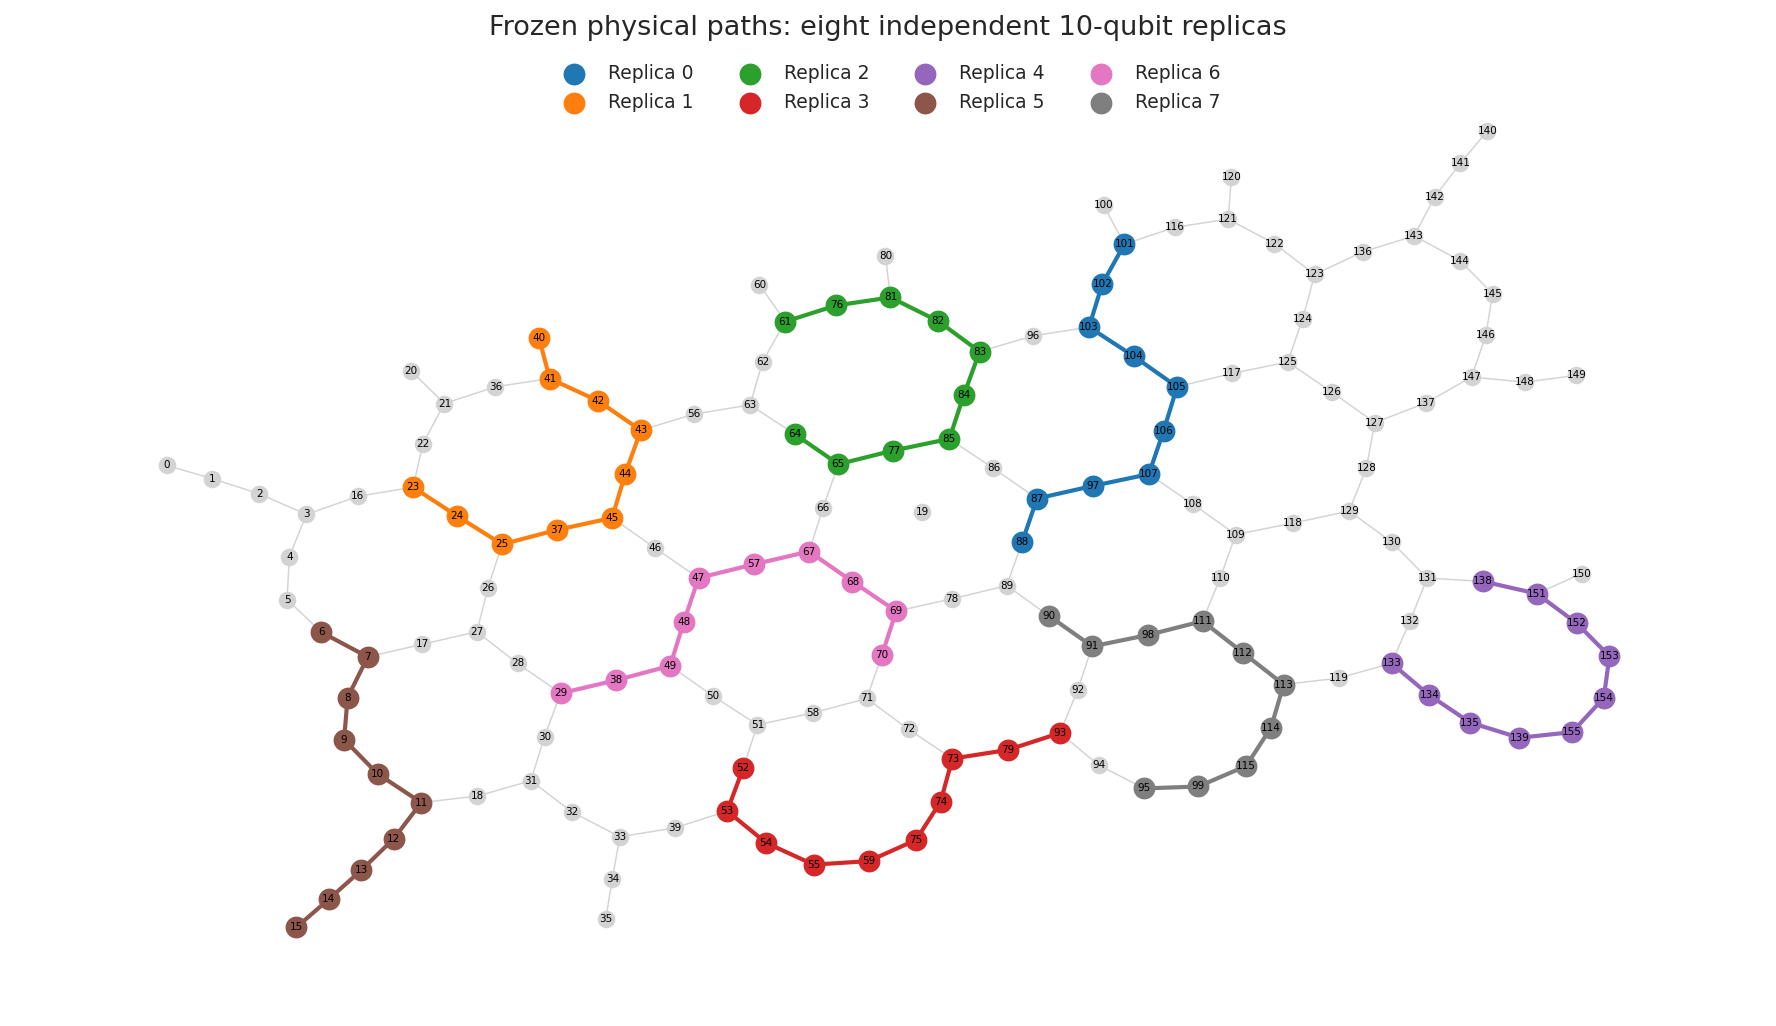

Acquisition budget (before cached requests):
{
  "start_epoch": 199,
  "total_target": 500,
  "replicas": 8,
  "total_pde_points": 128,
  "stages": [
    {
      "stage": "initial_calibration",
      "acquisitions": 0,
      "packed_configs_per_acquisition": 1024,
      "shots_per_config": 1024,
      "packed_configurations": 0,
      "composite_shots": 0,
      "sampler_jobs": 0
    },
    {
      "stage": "training_block_verification",
      "acquisitions": 31,
      "packed_configs_per_acquisition": 48,
      "shots_per_config": 1024,
      "packed_configurations": 1488,
      "composite_shots": 1523712,
      "sampler_jobs": 31
    },
    {
      "stage": "fixed_validation_monitor",
      "acquisitions": 62,
      "packed_configs_per_acquisition": 49,
      "shots_per_config": 1024,
      "packed_configurations": 3038,
      "composite_shots": 3110912,
      "sampler_jobs": 62
    },
    {
      "stage": "final_grid",
      "acquisitions": 1,
      "packed_configs_per_acquisition":

In [4]:
# Read metadata, construct and validate the circuit, and save the execution plan.
# This cell does NOT submit QPU jobs.
from qiskit_ibm_runtime import QiskitRuntimeService
from dataclasses import asdict
if (GRADIENT_METHOD, SURROGATE_STENCIL_MODE, SURROGATE_CALIBRATION_METHOD, TRAINING_MODE) != (
    "measured_surrogate_ste", "shared_center", "accumulated_lstsq", "surrogate_refine"):
    raise ValueError("This parallel experiment implements the frozen measured-surrogate protocol.")
if CHECKPOINT_INTERVAL != 1 or SURROGATE_RECALIBRATION_INTERVAL != BLOCK_EPOCHS:
    raise ValueError("Every epoch must be archived and recalibration must match the block boundary.")
if SHOTS != VERIFICATION_SHOTS:
    raise ValueError("SHOTS documents the training acquisition budget; keep it equal to VERIFICATION_SHOTS.")
SCIENTIFIC_CONFIG = ParallelScientificConfig(
    n_qubits=N_QUBITS, n_replicas=N_REPLICAS, n_collocation=N_COLLOCATION,
    validation_points=VALIDATION_POINTS, n_initial=N_INITIAL,
    n_initial_validation=N_INITIAL_VALIDATION, n_initial_test=N_INITIAL_TEST,
    L=L, Tfin=TFIN, nu=NU, initial_condition_mode=INITIAL_CONDITION_MODE,
    initial_condition_weight=INITIAL_CONDITION_WEIGHT, pre_neurons=PRE_NEURONS,
    pre_depth=PRE_DEPTH, post_neurons=POST_NEURONS, post_depth=POST_DEPTH,
    fixed_layer=FIXED_LAYER, fixed_layer_repeats=FIXED_LAYER_REPEATS,
    input_rotation_axis=INPUT_ROTATION_AXIS, angle_scale=ANGLE_SCALE, hx=HX, ht=HT,
    adaptive_collocation=ADAPTIVE_COLLOCATION, candidate_points=CANDIDATE_POINTS,
    uniform_fraction=UNIFORM_FRACTION, collocation_distribution=COLLOCATION_DISTRIBUTION,
    surrogate_derivatives=SURROGATE_DERIVATIVES,
    surrogate_calibration_points=SURROGATE_CALIBRATION_POINTS,
    surrogate_calibration_seed=SURROGATE_CALIBRATION_SEED,
    max_surrogate_support=MAX_SURROGATE_SUPPORT, max_calibration_points=MAX_CALIBRATION_POINTS,
    dtype=DTYPE)
TRAINING_OPTIONS = ParallelTrainingOptions(total_steps=ADAM_EPOCHS, seed=SEED, lr=LR,
    block_epochs=BLOCK_EPOCHS, refine_adam_epochs=REFINE_ADAM_EPOCHS,
    lbfgs_lr=LBFGS_LR, lbfgs_max_iter=LBFGS_MAX_ITER, lbfgs_max_eval=LBFGS_MAX_EVAL,
    lbfgs_history_size=LBFGS_HISTORY_SIZE, weight_decay=WEIGHT_DECAY, grad_clip=GRAD_CLIP,
    scheduler_patience=SCHEDULER_PATIENCE, scheduler_factor=SCHEDULER_FACTOR,
    scheduler_min_lr=SCHEDULER_MIN_LR, monitor_interval=MONITOR_INTERVAL,
    monitor_repetitions=MONITOR_REPETITIONS, calibration_shots=CALIBRATION_SHOTS,
    verification_shots=VERIFICATION_SHOTS, evaluation_shots=EVALUATION_SHOTS,
    evaluation_points=EVALUATION_POINTS, progress_interval=PROGRESS_INTERVAL, target_loss=TARGET_LOSS)
OUTPUT_ROOT = parallel_output_root(EXPERIMENT_ROOT_OVERRIDE, OUTPUT_ROOT_OVERRIDE)
if ACTION in ("resume", "evaluate", "diagnose"):
    SOURCE_CHECKPOINT = parallel_find_checkpoint(OUTPUT_ROOT,
        RESUME_CHECKPOINT if ACTION == "resume" else CHECKPOINT_PATH)
    SAVED_STATE = load_parallel_checkpoint(SOURCE_CHECKPOINT)
    RUN_DIRECTORY = (SOURCE_CHECKPOINT.parent.parent.parent
                     if SOURCE_CHECKPOINT.parent.name.startswith("epoch_") else SOURCE_CHECKPOINT.parent)
    if ACTION in ("evaluate", "diagnose"):
        SCIENTIFIC_CONFIG = ParallelScientificConfig(**SAVED_STATE["config"])
    saved_hardware = SAVED_STATE["protocol"]["hardware"]
    if IBM_BACKEND_NAME != saved_hardware["backend_name"]:
        raise ValueError("Set IBM_BACKEND_NAME to the checkpoint's saved backend: " + saved_hardware["backend_name"])
elif ACTION in ("train", "warm_start"):
    SOURCE_CHECKPOINT = None
    RUN_DIRECTORY = parallel_new_directory(OUTPUT_ROOT, RUN_NAME)
else:
    raise ValueError("Unknown ACTION.")
connection = {}
if IBM_TOKEN:
    connection.update(channel="ibm_quantum_platform", token=IBM_TOKEN)
if IBM_INSTANCE:
    connection["instance"] = IBM_INSTANCE
if IBM_ACCOUNT_NAME and not IBM_TOKEN:
    connection["name"] = IBM_ACCOUNT_NAME
IBM_SERVICE = QiskitRuntimeService(**connection)
del connection  # Credentials are never written into the scientific state.
IBM_BACKEND = IBM_SERVICE.backend(IBM_BACKEND_NAME)
QPU_RUNNER = ParallelIBMRunner(IBM_BACKEND, IBM_SERVICE, RUN_DIRECTORY,
    n_qubits=SCIENTIFIC_CONFIG.n_qubits, replicas=SCIENTIFIC_CONFIG.n_replicas,
    layouts=MANUAL_PHYSICAL_PATHS, min_separation=MIN_REPLICA_SEPARATION,
    optimization_level=OPTIMIZATION_LEVEL, seed_transpiler=SEED_TRANSPILER,
    max_configs_per_job=MAX_CONFIGS_PER_JOB,
    input_rotation_axis=SCIENTIFIC_CONFIG.input_rotation_axis,
    require_heron_r3=True, rep_delay=REP_DELAY,
    layout_search_trials=LAYOUT_SEARCH_TRIALS, allow_submit=False)
# Validate the complete polynomial budget before the first hardware acquisition.
_probe_surrogate = ReplicaTrigSurrogate(SCIENTIFIC_CONFIG.n_qubits, SCIENTIFIC_CONFIG.n_replicas,
    QPU_RUNNER.supports_by_replica, max_support=SCIENTIFIC_CONFIG.max_surrogate_support)
_probe_surrogate.make_initial_design(SCIENTIFIC_CONFIG.surrogate_calibration_points,
    SCIENTIFIC_CONFIG.surrogate_calibration_seed, SCIENTIFIC_CONFIG.max_calibration_points)
del _probe_surrogate
print("Run directory:", RUN_DIRECTORY)
print("Backend:", IBM_BACKEND.name)
print("Physical paths:", QPU_RUNNER.layouts)
print(json.dumps(QPU_RUNNER.compilation_report, indent=2))
plot_parallel_layout(QPU_RUNNER, show=SHOW_PLOTS)
if ACTION in ("train", "resume", "warm_start"):
    ACQUISITION_BUDGET = parallel_acquisition_budget(SCIENTIFIC_CONFIG, TRAINING_OPTIONS,
        MAX_CONFIGS_PER_JOB,
        start_epoch=SAVED_STATE["epoch"] if ACTION == "resume" else 0,
        calibrated=(SAVED_STATE["surrogate_state"]["version"] > 0) if ACTION == "resume" else False,
        evaluate=RUN_FINAL_QPU_EVALUATION)
    print("Acquisition budget (before cached requests):")
    print(json.dumps(ACQUISITION_BUDGET, indent=2))
    _pout_json(RUN_DIRECTORY / "latest_budget.json", ACQUISITION_BUDGET)
print("Training cell submits real IBM jobs. Resume the SAME run after interruption.")


## Execute the real-QPU experiment


In [5]:
# This cell submits real QPU acquisitions for the selected action.
# No QPU calls occur inside Adam or L-BFGS closures.
QPU_RUNNER.allow_submit = True
if ACTION in ("train", "resume", "warm_start"):
    RUN_RESULT = train_parallel_ibm(SCIENTIFIC_CONFIG, TRAINING_OPTIONS, QPU_RUNNER,
        RUN_DIRECTORY, action=ACTION, checkpoint=SOURCE_CHECKPOINT,
        warm_start_checkpoint=WARM_START_CHECKPOINT)
    ACTIVE_CHECKPOINT = RUN_RESULT["checkpoint"]
elif ACTION == "diagnose":
    DIAGNOSTIC_REPORT = diagnose_parallel_ibm(SOURCE_CHECKPOINT, QPU_RUNNER,
        repetitions=DIAGNOSTIC_REPETITIONS, shots=DIAGNOSTIC_SHOTS)
    print(json.dumps(DIAGNOSTIC_REPORT, indent=2))
    ACTIVE_CHECKPOINT = SOURCE_CHECKPOINT
else:
    ACTIVE_CHECKPOINT = SOURCE_CHECKPOINT
print("Checkpoint:", ACTIVE_CHECKPOINT)
print(json.dumps(QPU_RUNNER.request_summary(), indent=2))


Run directory: /home/erickcastro/projetos/meu_projeto/Experiment1Modified/CBPF_quantum_ibm_training_results_vol2_parallel8/20261028_111807_heron_parallel8_a35cfc0d
Starting at epoch 199; total target: 500; replicas: 8.
Epoch 200: lbfgs, train=0.00874458, monitor=0.0207285, lr=0.5


/tmp/ipykernel_1169258/4204195394.py:515: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  return SamplerV2(mode=self.backend, options=options)


Epoch 210: lbfgs, train=0.00969424, monitor=0.0170845, lr=0.5
Epoch 220: lbfgs, train=0.00550803, monitor=0.0202462, lr=0.5
Epoch 230: lbfgs, train=0.00442797, monitor=0.0107354, lr=0.5
Epoch 240: lbfgs, train=0.00336918, monitor=0.0302365, lr=0.5
Epoch 250: lbfgs, train=0.00433445, monitor=0.00808399, lr=0.5
Epoch 260: lbfgs, train=0.00348724, monitor=0.0168691, lr=0.5
Epoch 270: lbfgs, train=0.00409811, monitor=0.00744617, lr=0.5
Epoch 280: lbfgs, train=0.00396376, monitor=0.00902951, lr=0.5
Epoch 290: lbfgs, train=0.00309993, monitor=0.0124674, lr=0.5
Epoch 300: lbfgs, train=0.00349583, monitor=0.0121502, lr=0.5
Epoch 310: lbfgs, train=0.00277142, monitor=0.00822011, lr=0.5
Epoch 320: lbfgs, train=0.00293295, monitor=0.010354, lr=0.5
Epoch 330: lbfgs, train=0.00306696, monitor=0.00690822, lr=0.5
Epoch 340: lbfgs, train=0.00256133, monitor=0.00772152, lr=0.5
Epoch 350: lbfgs, train=0.00165401, monitor=0.0140505, lr=0.5
Epoch 390: lbfgs, train=0.00224781, monitor=0.00633669, lr=0.5
Ep

## Matched classical PINN


In [7]:
# Purely classical control: no IBM calls and no fitting to the FDM solution.
# Replay the actual saved hybrid point schedule, with the same total outer steps.
CLASSICAL_RESULT = None
if RUN_CLASSICAL_COMPARISON and ACTION != "diagnose":
    scientific_state = load_parallel_checkpoint(ACTIVE_CHECKPOINT)
    if scientific_state["epoch"] < 1:
        raise ValueError("Complete at least one hybrid epoch before running the comparison.")
    classical_directory = RUN_DIRECTORY / "classical_comparison"
    classical_action = CLASSICAL_ACTION
    if classical_action == "auto":
        exists = (classical_directory / "classical_checkpoint_last.pt").exists()
        classical_action = ("evaluate" if ACTION == "evaluate" else "resume" if exists else "train")
    classical_config = dict(scientific_state["config"], **scientific_state["options"])
    classical_config.update(classical_neurons=CLASSICAL_NEURONS, classical_depth=CLASSICAL_DEPTH)
    CLASSICAL_RESULT = run_matched_classical(classical_config,
        scientific_state["training_schedule"], scientific_state["fixed_sets"], classical_directory,
        total_steps=int(scientific_state["epoch"]), action=classical_action,
        progress_interval=PROGRESS_INTERVAL)
    print("Classical checkpoint:", CLASSICAL_RESULT["checkpoint"])


Classical step 1: adamw, training=0.641543, lr=0.003.
Classical step 10: adamw, training=0.523195, lr=0.003.
Classical step 20: adamw, training=0.435161, lr=0.003.
Classical step 30: adamw, training=0.363176, lr=0.003.
Classical step 40: adamw, training=0.31957, lr=0.003.
Classical step 50: adamw, training=0.306905, lr=0.003.
Classical step 60: adamw, training=0.297466, lr=0.003.
Classical step 70: adamw, training=0.286142, lr=0.003.
Classical step 80: adamw, training=0.293097, lr=0.003.
Classical step 90: adamw, training=0.28804, lr=0.003.
Classical step 100: adamw, training=0.2975, lr=0.003.
Classical step 110: lbfgs, training=0.146304, lr=0.5.
Classical step 120: lbfgs, training=0.110613, lr=0.5.
Classical step 130: lbfgs, training=0.124277, lr=0.5.
Classical step 140: lbfgs, training=0.117475, lr=0.5.
Classical step 150: lbfgs, training=0.124582, lr=0.5.
Classical step 160: lbfgs, training=0.124923, lr=0.5.
Classical step 170: lbfgs, training=0.0900509, lr=0.5.
Classical step 180: 

## Final-time comparison


/tmp/ipykernel_1169258/4204195394.py:515: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  return SamplerV2(mode=self.backend, options=options)


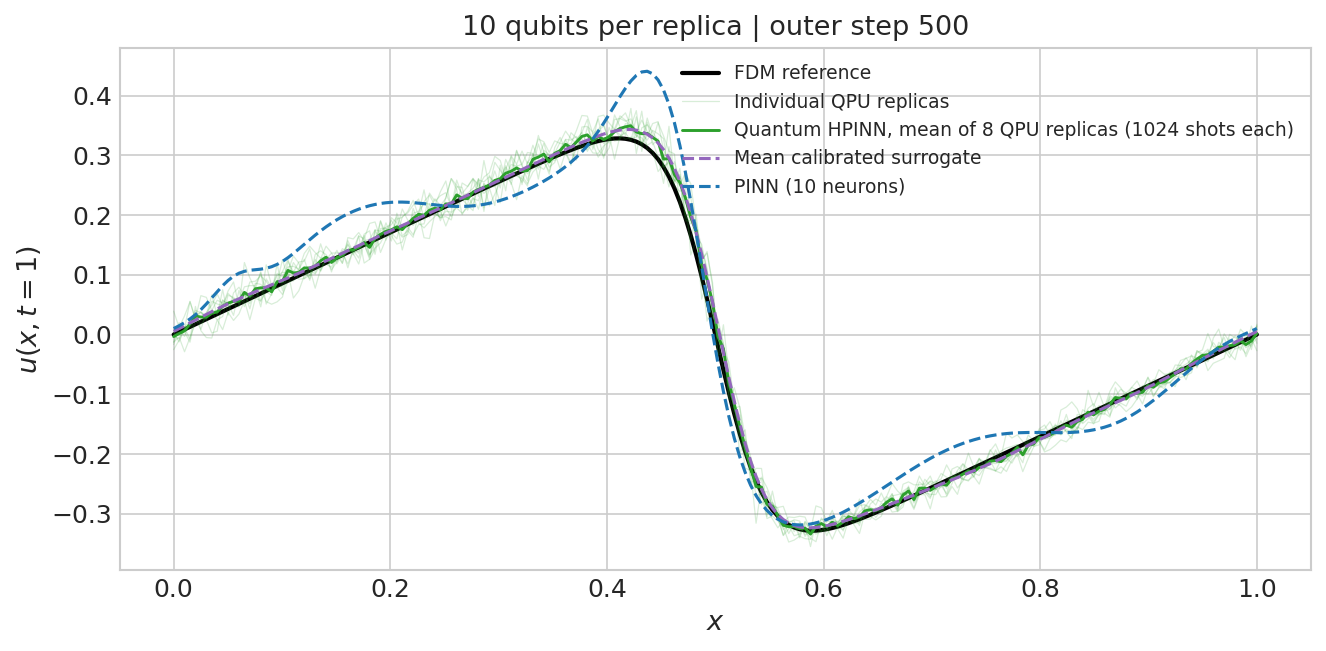

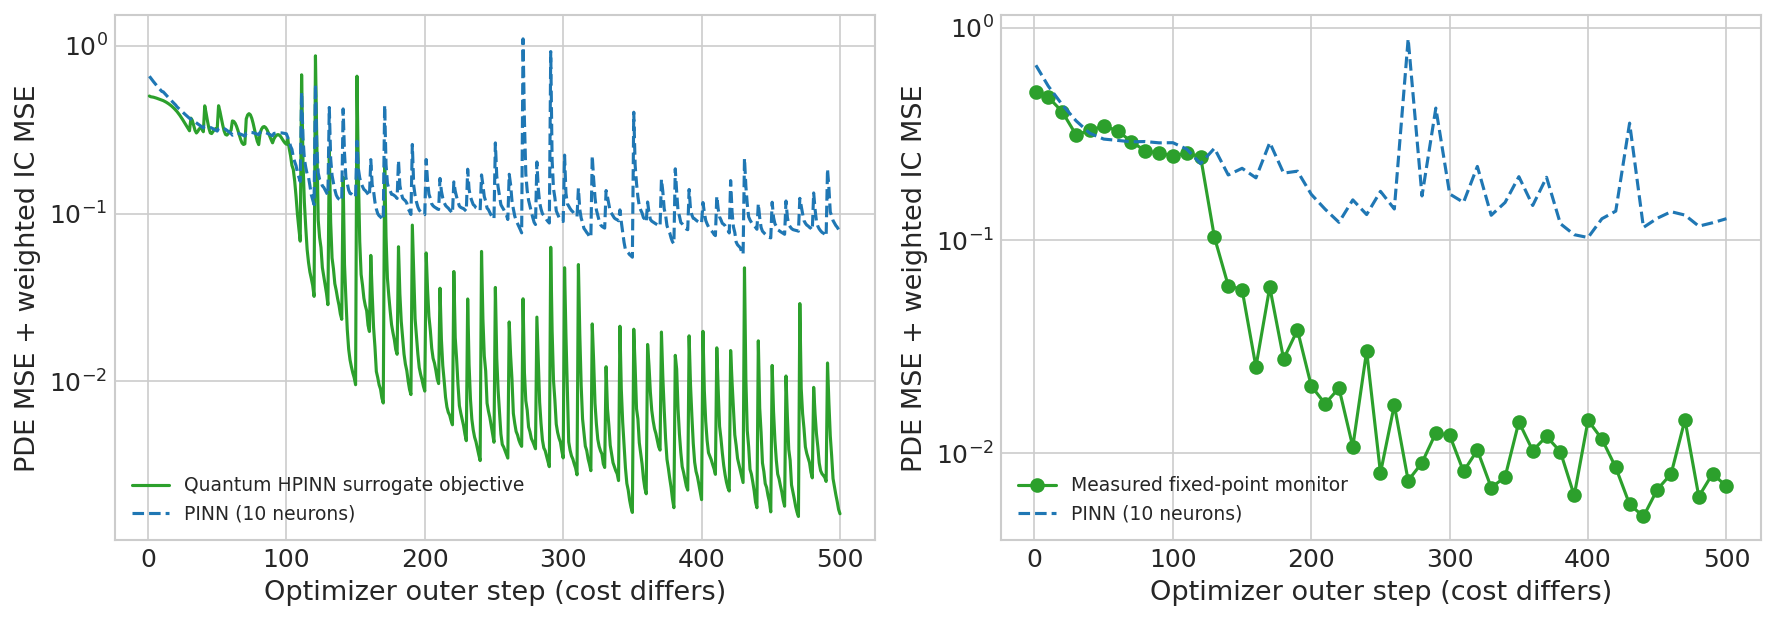

Comparison directory: /home/erickcastro/projetos/meu_projeto/Experiment1Modified/CBPF_quantum_ibm_training_results_vol2_parallel8/20261028_111807_heron_parallel8_a35cfc0d/evaluations/epoch_000500_97feac8da1539100_n200_s1024_qpu
{
  "epoch": 500,
  "shots": 1024,
  "surrogate_mse_by_replica": [
    0.00012349346374452595,
    0.00016207538706592968,
    0.00013183796501406886,
    0.00024878214660252755,
    0.00022216556077082943,
    0.00016945837837858215,
    0.00026965500632660845,
    6.211303781715686e-05
  ],
  "ensemble_note": "Descriptive mean across physical replicas; training optimizes individual replica residuals.",
  "request_key": "evaluation/epoch_000500/97feac8da1539100/n200_s1024",
  "qpu_mse_by_replica": [
    0.0003790089792041672,
    0.0003795913209948293,
    0.00033738191900343795,
    0.00043937888145219333,
    0.0003550901775512739,
    0.0004259679570526535,
    0.0004547795569567753,
    0.0002603061819024339
  ],
  "qpu_ensemble_mse": 0.00011322957099968481

In [8]:
# Final-grid measurements are an additional acquisition, independent of training.
# Each physical replica evaluates the same grid; exact reruns reuse stored jobs.
if ACTION != "diagnose":
    EVALUATION_REPORT = evaluate_parallel_ibm(ACTIVE_CHECKPOINT, QPU_RUNNER,
        shots=EVALUATION_SHOTS, n_points=EVALUATION_POINTS, show=SHOW_PLOTS,
        measure=RUN_FINAL_QPU_EVALUATION,
        classical_model=None if CLASSICAL_RESULT is None else CLASSICAL_RESULT["model"],
        classical_history=None if CLASSICAL_RESULT is None else CLASSICAL_RESULT["history"])
    print("Comparison directory:", EVALUATION_REPORT["directory"])
    print(json.dumps(EVALUATION_REPORT["metrics"], indent=2))


In [6]:
state = load_parallel_checkpoint(RUN_DIRECTORY / "checkpoint_last.pt")
print("Última época concluída:", state["epoch"])

Última época concluída: 500


## Continuing and recovering the experiment

After the one-step pilot, set `ACTION="resume"`, `ADAM_EPOCHS=500`, and the
printed `RESUME_CHECKPOINT` path. Keep `REFINE_ADAM_EPOCHS=100`. The first pilot
step is retained, as are Adam, L-BFGS, scheduler, RNG and surrogate states.
Reexecute preparation and training. The classical control automatically resumes
from its own last checkpoint and replays the newly saved hybrid blocks.

A pending job is recovered by resuming the same run. A canceled/failed job needs
an explicit retry decision; it is not silently replaced by a new paid job:

```python
# Use the exact request key and chunk number printed in the error/manifest.
# QPU_RUNNER.explicitly_authorize_retry(request_key, chunk_index)
# Then resume the SAME run.
```

If connection loss happened between submission and saving the job ID, locate the
job by the saved recovery tag in the IBM dashboard and attach that exact job:

```python
# QPU_RUNNER.recover_job(request_key, chunk_index, "actual_job_id")
```

Saved artifacts include:
- `hardware/`: compiled QPY circuit, physical layout, calibration snapshot and versions.
- `qpu_requests/`: exact angle arrays, replica IDs, packing maps, IBM job IDs,
  counts, paired raw bitstrings, metadata, usage and cached measured means.
- `epochs/epoch_XXXXXX/`: full checkpoint, network parameters, point-owner pairs and metrics.
- `checkpoint_last.pt`, `checkpoint_best.pt`, `checkpoint_final.pt`: recovery/selection aliases.
- `training_history.csv`, block selections, calibration fits and monitor diagnostics.
- `classical_comparison/`: independent classical states and per-epoch parameters.
- `evaluations/`: numerical reference, every replica, descriptive mean, classical
  predictions, metrics, CSV/NPZ and PNG/PDF plots.

The initial hardware snapshot fixes the layout and compiled program, but it does
not freeze real device noise. Accumulated least squares retains historical data;
monitor feature errors and drift before extending a long run. Eight regions with
minimum separation are a topology constraint, not a proof of absent cross-talk.

The original Aer notebook SHA-256 is recorded in the build manifest for provenance.
No simulator training data are represented as real hardware measurements.


In [ ]:
2+2